# Preprocesamiento de datos

### Profesorado

* Juan Carlos Alfaro Jiménez
* José Miguel Puerta Callejón

### Objetivo

El objetivo de esta libreta es demostrar un flujo de trabajo completo de preprocesamiento de datos, desde la carga inicial hasta la preparación final para un modelo de aprendizaje automático.

No hay que perder de vista que el preprocesamiento **no es un fin en sí mismo**: su objetivo final es **mejorar la capacidad predictiva de los modelos**. Por eso, antes de empezar, entrenaremos un modelo de referencia con el preprocesamiento mínimo imprescindible y, al final, comprobaremos si todo el trabajo realizado ha merecido la pena.

### Pasos del preprocesamiento

A lo largo de esta libreta, cubriremos sistemáticamente:

1. **Carga y comprensión inicial:** Importar librerías, cargar datos y revisión inicial.
2. **Modelo de referencia:** Entrenar un clasificador con el preprocesamiento mínimo imprescindible para saber de dónde partimos.
3. **Análisis exploratorio de datos:** Entender la distribución de las variables, identificar correlaciones y visualizar patrones.
4. **Manejo de valores faltantes:** Identificar valores nulos (explícitos e implícitos) y aplicar técnicas de imputación.
5. **Codificación de variables categóricas:** Aplicar los codificadores según corresponda.
6. **Detección y tratamiento de valores extremos:** Identificar valores atípicos en variables numéricas.
7. **Transformación de características:** Corregir la asimetría en variables numéricas.
8. **Escalado de características:** Estandarizar o normalizar las variables numéricas para que el modelo converja correctamente.
9. **Ingeniería de características:** Creación de nuevas variables predictoras a partir de las existentes (discretización, transformaciones personalizadas, etc.).
10. **Modelado:** Construir un `Pipeline` de preprocesamiento y entrenar el modelo.
11. **Evaluación:** Evaluar el rendimiento del modelo y compararlo con el modelo de referencia.

A lo largo de la libreta encontrarás varios bloques `TODO`, en recuadros verdes. No son necesarios para que la libreta funcione: puedes ejecutarla de principio a fin sin resolverlos. Están pensados para que practiques por tu cuenta y algunos de sus resultados se te preguntarán en el cuestionario.

---

## 1. Configuración inicial

Antes de comenzar, vamos a importar todas las librerías a utilizar con el objetivo de tener la libreta organizada desde el principio:

In [1]:
# Standard
import warnings

# Third party
import matplotlib.pyplot as plt
import missingno as msno
import pandas as pd
import numpy as np
import seaborn as sns
from dython.nominal import associations
from sklearn import set_config
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, roc_auc_score

Además, configuramos la visualización de las gráficas:

In [2]:
%matplotlib inline
figsize = (12, 7)  # Width, height in inches
palette = "colorblind"  # Palette definition
plt.rcParams["figure.figsize"] = figsize
sns.set_palette(palette)

A su vez, fijamos una semilla para que los experimentos sean reproducibles:

In [3]:
random_state = seed = 41686

Vamos a indicarle a `scikit-learn` que la salida de sus transformadores sea un `DataFrame` de `pandas` siempre que sea posible, en lugar de un *array* de `NumPy` (que es el comportamiento por defecto). Hacemos esto ahora porque, aunque no afecta al modelo final, hace que el **proceso de definir y depurar los pasos de preprocesamiento sea mucho más cómodo**. Nos permitirá inspeccionar la salida de nuestros `Pipeline` en cualquier etapa y ver un `DataFrame` con nombres de columna legibles, facilitando la verificación de que nuestra lógica es correcta, en lugar de tener que descifrar un *array* numérico anónimo.

In [4]:
transform_output = "pandas"  # Pandas output
set_config(transform_output=transform_output)

Por último, filtramos los mensajes de advertencia para evitar salidas demasiado largas en la libreta:

In [5]:
action = "ignore"  # Never print matching warnings
warnings.filterwarnings(action)

---

## 2. Carga y división de los datos

Vamos a cargar el conjunto de datos [`Bank Marketing`](https://archive.ics.uci.edu/dataset/222/bank+marketing). Este conjunto registra los resultados de una campaña completa de marketing directo (llamadas telefónicas) de un banco portugués, diseñada para que los clientes suscribieran un depósito a plazo fijo.

El problema de negocio es **optimizar las campañas de marketing** identificando de antemano qué clientes tienen mayor probabilidad de suscribirse al producto. Desde la perspectiva del aprendizaje automático, este es un problema clásico de **clasificación binaria supervisada**. El objetivo final es construir un modelo (en nuestro caso, una **regresión logística**) que aprenda de las características del cliente y de la campaña para predecir si un cliente dirá «sí» o «no».

La variable que intentamos predecir es `y`, categórica, con valores `"yes"` (el cliente se suscribió) y `"no"` (el cliente no se suscribió).

Las variables predictoras se pueden agrupar lógicamente en tres bloques:

**Datos del cliente**

* `age` (numérica): Edad del cliente.
* `job` (categórica): Tipo de trabajo.
* `marital` (categórica): Estado civil.
* `education` (categórica): Nivel educativo.
* `default` (categórica): ¿Tiene crédito en impago?
* `balance` (numérica): Saldo medio anual, en euros.
* `housing` (categórica): ¿Tiene un préstamo hipotecario?
* `loan` (categórica): ¿Tiene un préstamo personal?

**Datos del último contacto**

* `contact` (categórica): Tipo de comunicación del contacto.
* `day` (numérica): Día del último contacto.
* `month` (categórica): Mes del último contacto.
* `duration` (numérica): Duración del último contacto, en segundos.

**Historial de campañas**

* `campaign` (numérica): Número de contactos realizados durante esta campaña para este cliente.
* `pdays` (numérica): Días transcurridos desde el último contacto de una campaña previa.
* `previous` (numérica): Número de contactos realizados antes de esta campaña para este cliente.
* `poutcome` (categórica): Resultado de la campaña previa.

In [6]:
url = "https://raw.githubusercontent.com/haihapham/Bank-Marketing-Campaign/refs/heads/main/data/Bank%20Marketing%20Campaign_Data.csv"  # Dataset URL
index_col = 0  # Column to use as row label

data = pd.read_csv(url, index_col=index_col)

# Display n random samples instead of the first n to have a better idea of the data
n = 5  # Number of items from axis to return
data.sample(n, random_state=random_state)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3973,32,technician,single,tertiary,no,192,yes,no,unknown,16,may,303,5,-1,0,unknown,no
26858,51,admin.,married,secondary,no,0,no,no,telephone,20,nov,96,5,-1,0,unknown,no
22676,32,technician,married,secondary,yes,4,yes,yes,cellular,25,aug,132,8,-1,0,unknown,no
14080,41,technician,married,secondary,no,-172,yes,yes,cellular,11,jul,132,2,-1,0,unknown,no
33530,36,admin.,married,secondary,no,421,yes,no,cellular,20,apr,246,2,334,3,other,no


### 2.1. División estratégica: conjuntos de entrenamiento y prueba

Antes de transformar o analizar en profundidad cualquier dato, debemos realizar el paso metodológico más importante: **separar nuestro conjunto de datos en entrenamiento y prueba**.

#### ¿Por qué ahora?

Para garantizar una evaluación honesta y robusta de nuestro modelo.

* El conjunto de **entrenamiento** (`X_train`, `y_train`) será utilizado para *todo*: análisis exploratorio, imputación de valores faltantes, detección de valores extremos, escalado y, por supuesto, el entrenamiento del modelo.
* El conjunto de **prueba** (`X_test`, `y_test`) se mantendrá «guardado bajo llave» y completamente intacto. No lo miraremos ni lo usaremos para tomar ninguna decisión de preprocesamiento.

De esta forma, simulamos un escenario real donde el modelo se enfrenta a datos que nunca ha visto, previniendo la **fuga de datos** (*data leakage*). Si calculáramos, por ejemplo, la media para escalar usando el conjunto de datos completo, el conjunto de prueba ya habría «contaminado» nuestro preprocesamiento.

Usaremos una división estratificada (`stratify=y`) para asegurar que la proporción de `"yes"` y `"no"` sea la misma tanto en el conjunto de entrenamiento como en el de prueba, lo cual es vital en problemas de clasificación (especialmente si las clases están desbalanceadas).

In [7]:
# Separate features and target variable
target = "y"  # Target variable name
axis = "columns"  # Drop labels from columns
X = data.drop(target, axis = axis)
y = data[target]

# Divide the dataset into training and testing sets with stratification
test_size = 0.2  # Proportion of the dataset to include in the test split
stratify = y  # Class labels for stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=stratify)

In [8]:
X_train.sample(n, random_state=random_state)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
11567,51,unemployed,married,secondary,no,-267,no,yes,unknown,19,jun,208,2,-1,0,unknown
20636,42,technician,married,tertiary,no,250,no,yes,cellular,12,aug,213,3,-1,0,unknown
16686,52,blue-collar,married,secondary,no,3510,yes,no,telephone,24,jul,193,7,-1,0,unknown
23674,34,technician,married,secondary,no,298,no,no,cellular,28,aug,42,10,-1,0,unknown
5572,33,management,married,tertiary,no,0,yes,no,unknown,23,may,57,5,-1,0,unknown


In [9]:
y_train.sample(n, random_state=random_state)

11567    no
20636    no
16686    no
23674    no
5572     no
Name: y, dtype: str

In [10]:
X_test.sample(n, random_state=random_state)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
4800,34,blue-collar,single,secondary,no,558,yes,no,unknown,21,may,43,1,-1,0,unknown
31730,28,technician,single,secondary,no,922,yes,no,cellular,7,apr,304,1,-1,0,unknown
3579,45,blue-collar,divorced,primary,no,749,yes,no,unknown,15,may,242,6,-1,0,unknown
32785,35,admin.,married,secondary,no,437,yes,no,cellular,17,apr,123,1,-1,0,unknown
33888,51,housemaid,married,primary,no,618,yes,yes,cellular,30,apr,277,1,85,1,failure


In [11]:
y_test.sample(n, random_state=random_state)

4800     no
31730    no
3579     no
32785    no
33888    no
Name: y, dtype: str

In [12]:
normalize = True  # Return proportions instead of frequencies
y_train_proportions = y_train.value_counts(normalize=normalize)
y_test_proportions = y_test.value_counts(normalize=normalize)

objs = {"Entrenamiento": y_train_proportions, "Prueba": y_test_proportions}  # Class proportions of each set
axis = "columns"  # Concatenate along the columns
pd.concat(objs, axis=axis)

,Entrenamiento,Prueba
y,,
no,0.883018,0.883003
yes,0.116982,0.116997


Gracias a la estratificación, las proporciones de la clase objetivo son prácticamente idénticas en ambos conjuntos.

**A partir de este punto, guardamos `X_test` y `y_test` y solo los usaremos para evaluar modelos, nunca para tomar decisiones.**

Todo el análisis y preprocesamiento se realizará **únicamente** sobre `X_train` y `y_train`.

### 2.2. Modelo de referencia

Antes de empezar con el análisis exploratorio y el preprocesamiento, conviene recordar **para qué** hacemos todo esto. El preprocesamiento no es un fin en sí mismo: su objetivo final es **mejorar la capacidad predictiva de los modelos**. Cualquier transformación que apliquemos (imputar, codificar, transformar, escalar, crear nuevas variables, etc.) solo estará justificada si, al final, el modelo predice mejor.

Para poder comprobarlo necesitamos un punto de partida con el que comparar. Por eso, lo primero que haremos es entrenar un **modelo de referencia**: una regresión logística con el **preprocesamiento mínimo imprescindible** para que el modelo pueda entrenarse. Al final de la libreta compararemos este modelo con los obtenidos tras todo el preprocesamiento, para verificar que el esfuerzo ha merecido la pena.

¿Cuál es ese preprocesamiento mínimo? La implementación de la regresión logística de `scikit-learn` exige que:

* Todas las variables de entrada sean **numéricas**. Por tanto, debemos codificar las variables categóricas. Usaremos `OneHotEncoder`, que no impone ningún orden entre las categorías.
* No haya **valores faltantes explícitos** (`NaN`). Como veremos en el análisis exploratorio, este conjunto de datos no los tiene, por lo que no necesitamos imputar.

Nada más: no escalaremos, no transformaremos, no crearemos variables nuevas y usaremos los hiperparámetros por defecto del modelo.

<div class="alert alert-block alert-warning">

La única variable que excluiremos es `duration`. No es una decisión de preprocesamiento, sino de **definición del problema**: queremos predecir qué clientes se suscribirán *antes* de llamarles, y la duración de la llamada solo se conoce cuando la llamada ha terminado. Volveremos sobre ello en el análisis de correlaciones (sección 3.5).

</div>

In [13]:
numerical_features_baseline = ["age", "balance", "day", "campaign", "pdays", "previous"]
categorical_features_baseline = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

Codificamos las variables categóricas. Fíjate en que el codificador **se ajusta únicamente con `X_train`** (`.fit_transform()`) y después se aplica, sin volver a ajustarlo, a `X_test` (`.transform()`). Así evitamos la fuga de datos incluso en el modelo más sencillo. Más adelante (sección 5) veremos cómo automatizar este proceso con un `Pipeline`.

In [14]:
handle_unknown = "ignore"  # When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros
sparse_output = False  # Return dense array instead of sparse matrix
encoder_baseline = OneHotEncoder(handle_unknown=handle_unknown, sparse_output=sparse_output)

X_train_categorical_baseline = X_train[categorical_features_baseline]
X_test_categorical_baseline = X_test[categorical_features_baseline]
X_train_encoded_baseline = encoder_baseline.fit_transform(X_train_categorical_baseline)
X_test_encoded_baseline = encoder_baseline.transform(X_test_categorical_baseline)

# Join the untouched numerical features with the encoded categorical features
X_train_numerical_baseline = X_train[numerical_features_baseline]
X_test_numerical_baseline = X_test[numerical_features_baseline]
axis = "columns"  # Concatenate along the columns

objs = [X_train_numerical_baseline, X_train_encoded_baseline]  # Training features to concatenate
X_train_baseline = pd.concat(objs, axis=axis)

objs = [X_test_numerical_baseline, X_test_encoded_baseline]  # Test features to concatenate
X_test_baseline = pd.concat(objs, axis=axis)

X_train_baseline.sample(n, random_state=random_state)

,age,balance,day,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
11567,51,-267,19,2,-1,0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
20636,42,250,12,3,-1,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
16686,52,3510,24,7,-1,0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
23674,34,298,28,10,-1,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5572,33,0,23,5,-1,0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Entrenamos la regresión logística con sus hiperparámetros por defecto:

In [15]:
classifier_baseline = LogisticRegression(random_state=random_state)
classifier_baseline.fit(X_train_baseline, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",41686
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the followin

Y la evaluamos en el conjunto de prueba. En la sección 7 se explican en detalle las métricas que usaremos (precisión, sensibilidad, *F1-score* y *ROC-AUC*).

<div class="alert alert-block alert-info">

Usamos aquí el conjunto de prueba **solo para medir el punto de partida**, no para tomar ninguna decisión de preprocesamiento. Si quisiéramos usar estas cifras para elegir entre alternativas, lo correcto sería emplear un conjunto de validación o validación cruzada.

</div>

In [16]:
y_pred_baseline = classifier_baseline.predict(X_test_baseline)
y_prob_baseline = classifier_baseline.predict_proba(X_test_baseline)[:, 1]

In [17]:
target_names = ["no", "yes"]  # Class names for the target variable
classification_report_baseline = classification_report(y_test, y_pred_baseline, target_names=target_names)

print(classification_report_baseline)

              precision    recall  f1-score   support

          no       0.88      1.00      0.94      7985
         yes       0.59      0.02      0.04      1058

    accuracy                           0.88      9043
   macro avg       0.74      0.51      0.49      9043
weighted avg       0.85      0.88      0.83      9043



In [18]:
auc_baseline = roc_auc_score(y_test, y_prob_baseline)
auc_baseline

0.7185335689673337

A primera vista, una tasa de acierto de `0.88` puede parecer un buen resultado. Sin embargo, la sensibilidad para la clase `"yes"` es prácticamente nula (`0.02`): el modelo casi nunca predice que un cliente se va a suscribir, que es justo lo que nos interesa. Su *ROC-AUC* es `0.72`.

**Este es el listón que el preprocesamiento debe superar.** Lo retomaremos en la sección 7.

<div class="alert alert-block alert-success">

**`TODO 1`.** Los mensajes de advertencia están desactivados en esta libreta (sección 1), por lo que `scikit-learn` no nos avisa de ciertos problemas durante el entrenamiento.

Consulta el número de iteraciones que ha realizado el optimizador del modelo de referencia (atributo `n_iter_`) y compáralo con el número máximo de iteraciones permitido (hiperparámetro `max_iter`).

* ¿Qué te dice esta comparación?
* ¿Qué paso del preprocesamiento que veremos más adelante crees que ayudaría y por qué? Piensa en lo que se vio sobre descenso por gradiente cuando las variables tienen escalas muy diferentes.

</div>

In [19]:
# TODO 1: Inspect the number of iterations performed by the optimizer of "classifier_baseline"
# and compare it with the maximum number of iterations allowed

<div class="alert alert-block alert-success">

**`TODO 2`.** Entrena una copia del modelo de referencia que **sí** incluya `duration` (con el mismo preprocesamiento mínimo) y calcula su *ROC-AUC* en el conjunto de prueba. Anota el valor obtenido (con dos decimales).

* ¿Por qué ese resultado, aparentemente mucho mejor, no sería alcanzable cuando el modelo se use en producción para decidir a quién llamar?

Usa nombres de variables nuevos (por ejemplo, con el sufijo `_duration`) para no sobrescribir los del modelo de referencia.

</div>

In [20]:
# TODO 2: Train the baseline model including "duration" and compute its ROC-AUC on the test set
# numerical_features_duration = ...
# X_train_duration = ...
# X_test_duration = ...
# classifier_duration = ...
# auc_duration = ...

---

## 3. Análisis exploratorio de datos

Ahora que hemos aislado nuestros datos de prueba y sabemos de dónde partimos, comienza el verdadero trabajo de preprocesamiento. Todo el análisis, decisiones y transformaciones se basarán **únicamente** en `X_train` y `y_train`.

Nuestro primer paso es un análisis exploratorio de datos profundo para entender la naturaleza de nuestras variables.

### 3.1. Análisis de la variable objetivo

Primero, examinemos la variable que queremos predecir. Es crucial saber qué tan balanceadas están las clases. Un desbalance severo puede requerir técnicas especiales (como el remuestreo o el ajuste de pesos del modelo), aunque en esta libreta nos centraremos en el preprocesamiento de las características.

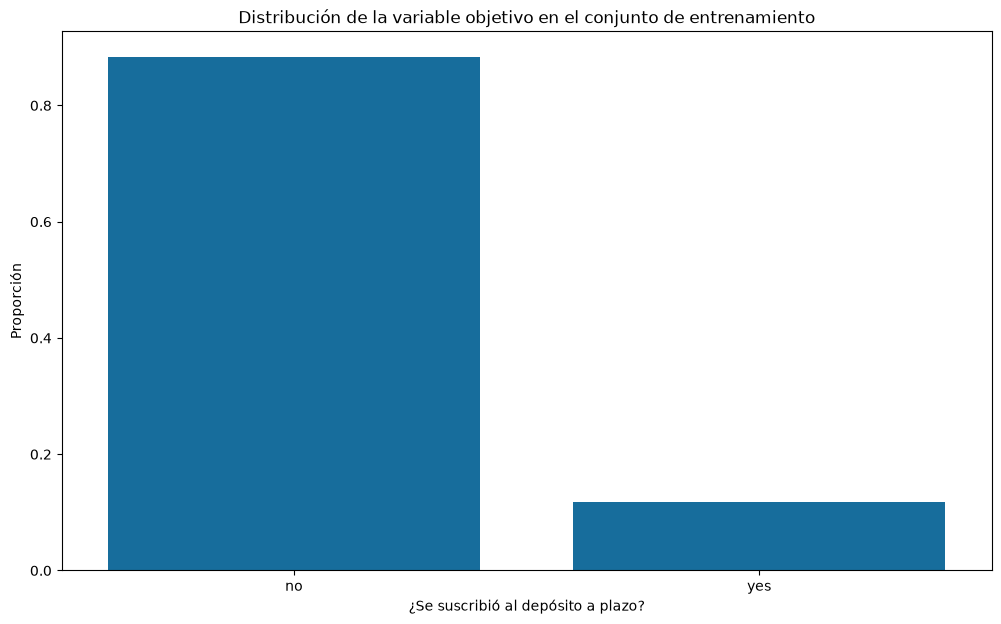

In [21]:
# Plot the distribution of the target variable
stat = "proportion"  # Normalize to proportions
title = "Distribución de la variable objetivo en el conjunto de entrenamiento"  # Text to use for the title
xlabel = "¿Se suscribió al depósito a plazo?"  # Text to use for the x-axis label
ylabel = "Proporción"  # Text to use for the y-axis label
sns.countplot(x=y_train, stat=stat)
plt.title(title)
plt.xlabel(xlabel)
plt.ylabel(ylabel)
plt.show()

El conjunto de datos está **desbalanceado**. Esto impactará directamente en la evaluación del modelo: la tasa de acierto, por sí sola, **no será una métrica fiable**. Un modelo que prediga siempre `"no"` (la clase mayoritaria) obtendría una alta tasa de acierto, pero sería inútil para el negocio. Por lo tanto, deberemos priorizar métricas como la **sensibilidad** o el *F1-score* sobre la clase de interés (`"yes"`).

### 3.2. Análisis de las variables predictoras

#### 3.2.1. Numéricas

Ahora, veamos las variables numéricas en `X_train`. Usaremos `.describe()` para obtener estadísticas clave. Buscamos:

* **Escalas:** Diferencias drásticas en los rangos.
* **Valores extremos:** Diferencias grandes entre el 75% (`Q3`) y el máximo (`max`).
* **Asimetría:** Si la media es muy diferente de la mediana (`Q2`).

In [22]:
include = ["int64", "float64"]  # Data types to include
numerical_features = X_train.select_dtypes(include=include).columns.tolist()
X_train[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,36168.0,40.930878,10.640176,18.0,33.0,39.0,48.0,95.0
balance,36168.0,1365.683809,3100.818922,-8019.0,70.0,444.0,1425.0,102127.0
day,36168.0,15.811436,8.328721,1.0,8.0,16.0,21.0,31.0
duration,36168.0,258.755143,257.603572,0.0,103.0,180.0,319.0,3881.0
campaign,36168.0,2.768829,3.114590,1.0,1.0,2.0,3.0,63.0
pdays,36168.0,40.104098,100.231377,-1.0,-1.0,-1.0,-1.0,854.0
previous,36168.0,0.568403,1.877823,0.0,0.0,0.0,0.0,55.0


La tabla `.describe()` ya nos da pistas claras.

Lo primero que observamos es el `count`: para todas las variables numéricas, el `count` coincide exactamente con el número total de instancias en nuestro conjunto de entrenamiento, lo que indica que no existen valores perdidos explícitos (`NaN`).

A continuación, vemos que, por ejemplo, `balance` tiene una media muy diferente de su mediana y un máximo muy alejado del 75%, lo que sugiere una fuerte **asimetría y valores extremos**.

Aunque estas estadísticas son muy útiles para una detección rápida, no nos muestran la *forma* completa de la distribución. Un solo valor extremo puede sesgar la media, pero un histograma nos muestra *cuántos* valores extremos hay y cómo de «larga» es esa cola.

Para confirmar esto visualmente, podemos ayudarnos de **histogramas** (para ver la distribución y asimetría) y **diagramas de caja** (para identificar valores extremos).

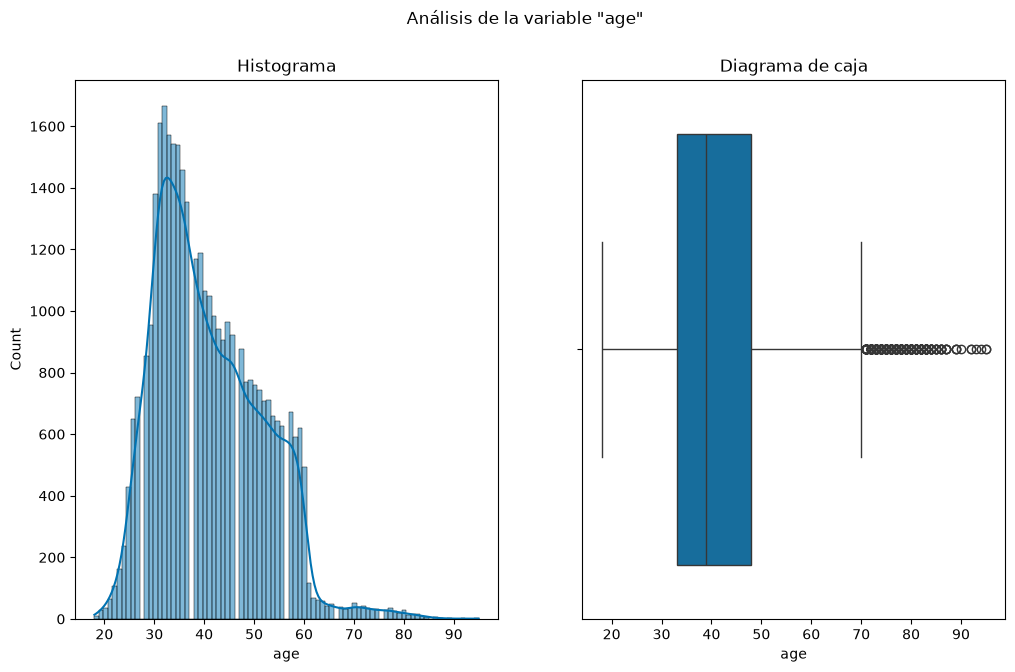

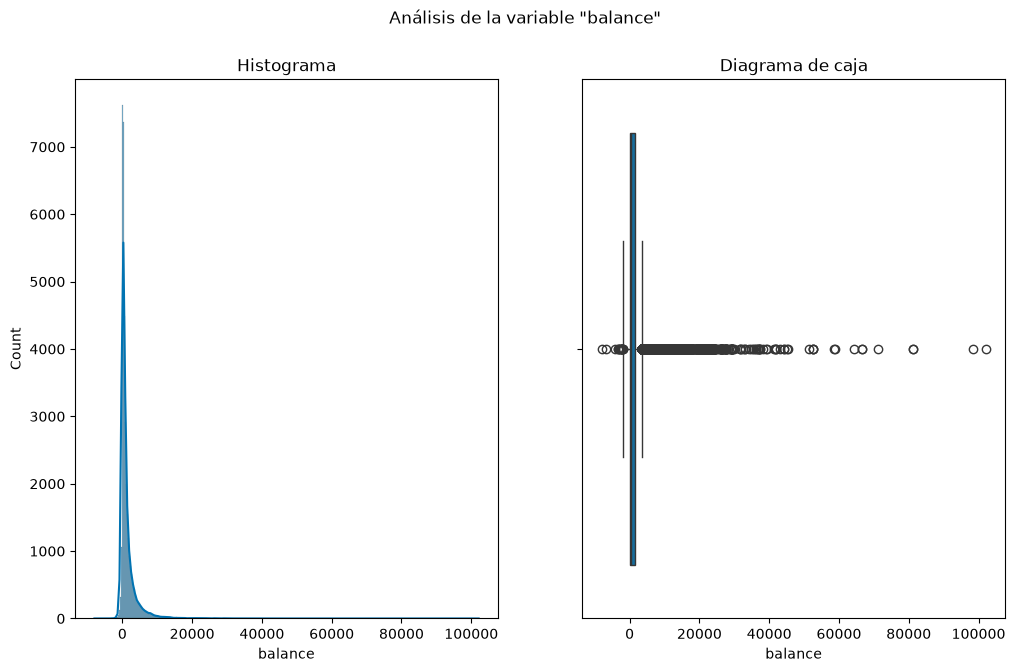

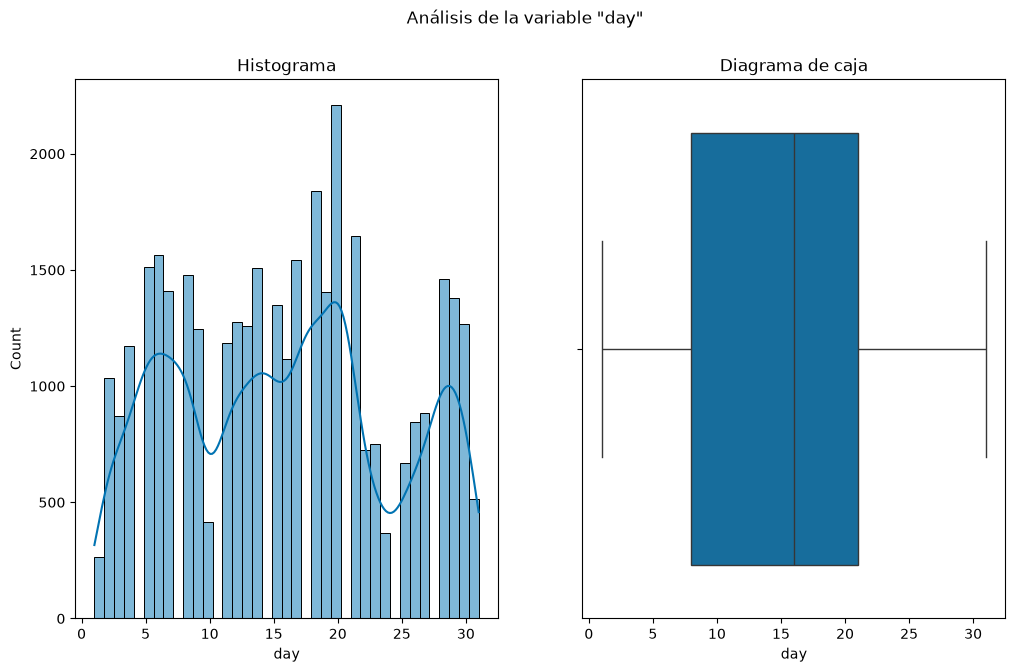

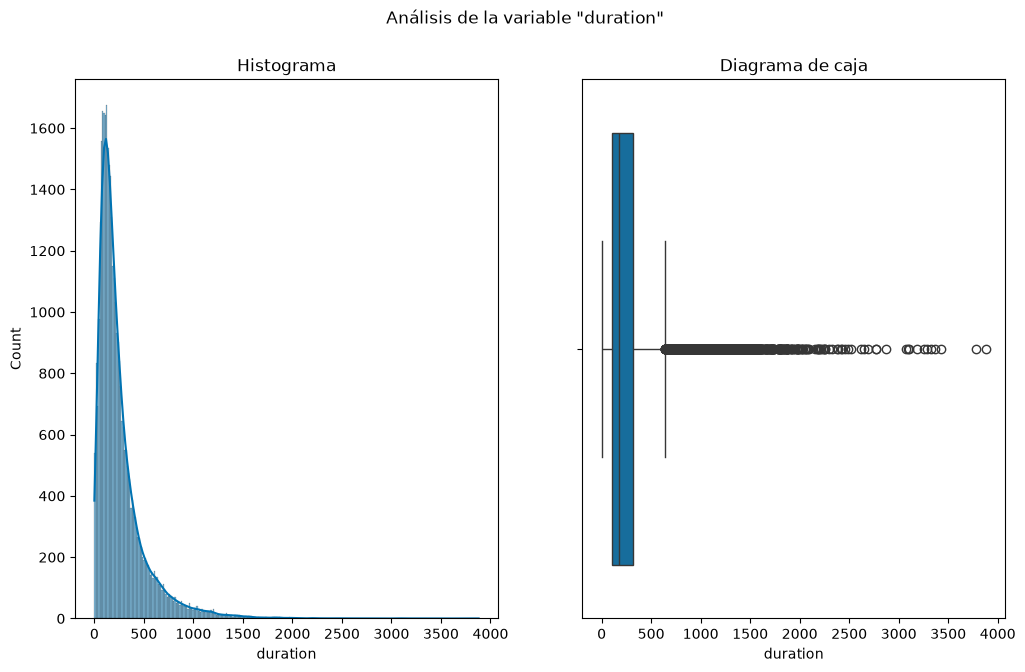

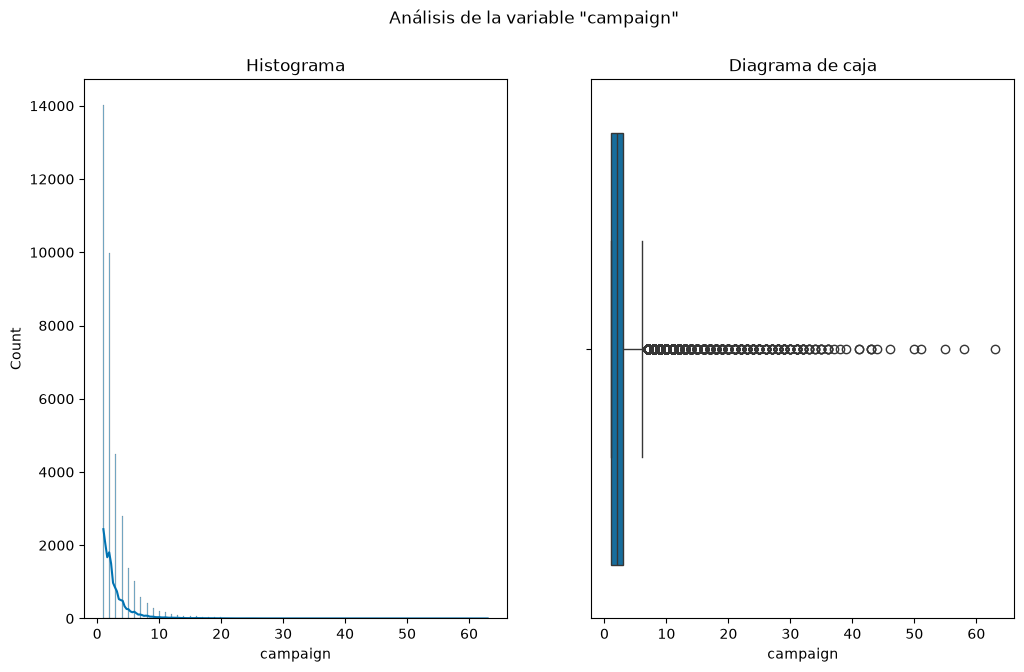

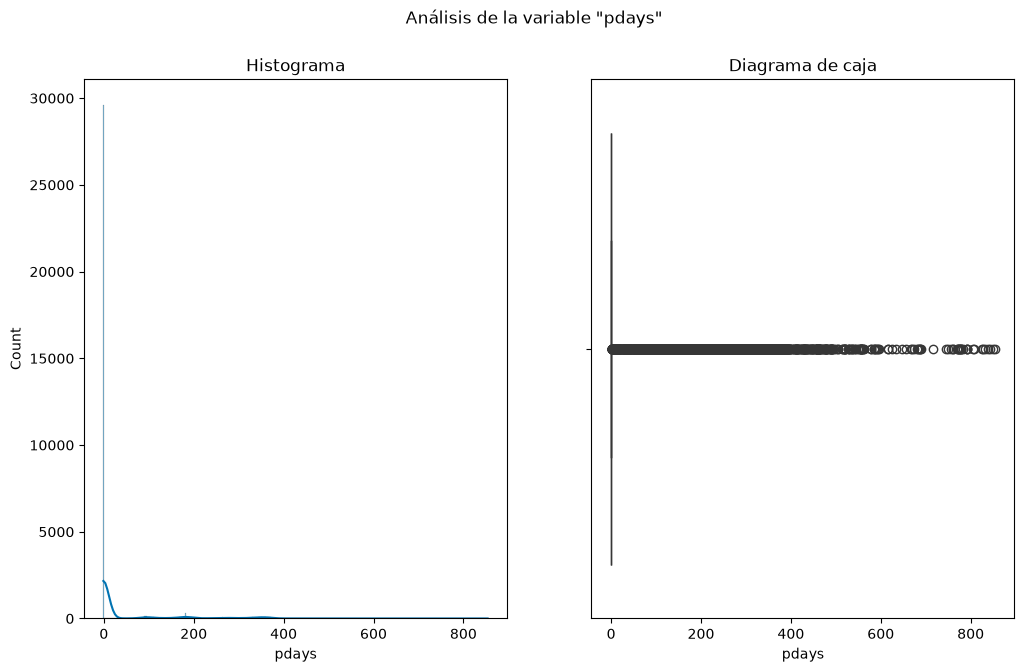

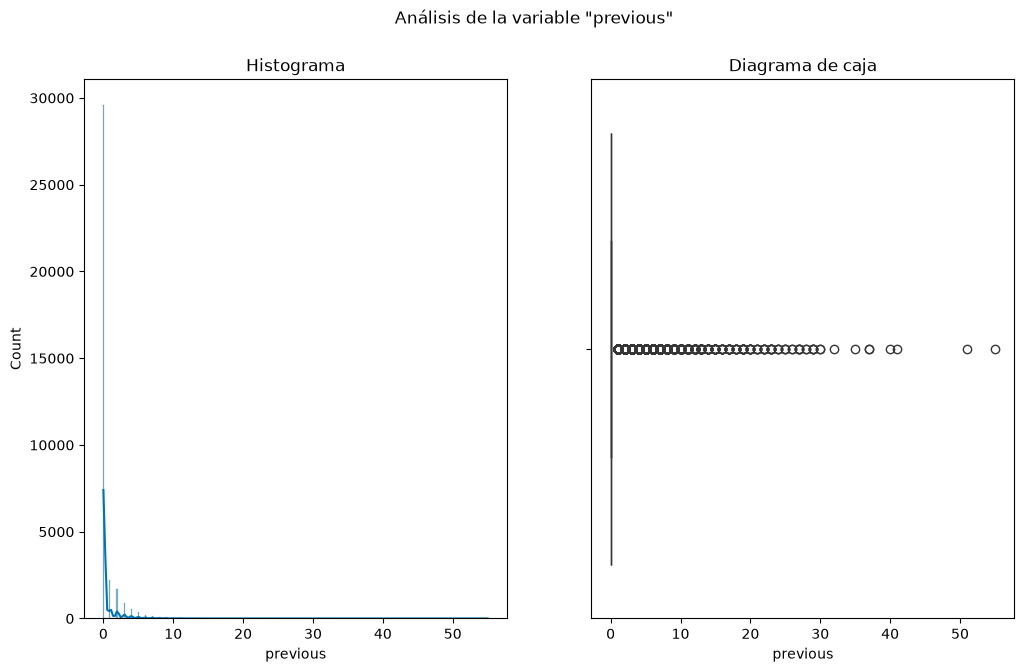

In [23]:
# Create plots
for column in numerical_features:
    # Set up the figure
    plt.figure()

    # Plot 1: Histogram
    plt.subplot(1, 2, 1)
    x = X_train[column]
    kde = True  # Compute a kernel density estimate to smooth the distribution
    title = f"Histograma"
    sns.histplot(x=x, kde=kde)
    plt.title(title)

    # Plot 2: Boxplot
    plt.subplot(1, 2, 2)
    x = X_train[column]
    title = f"Diagrama de caja"
    sns.boxplot(x=x)
    plt.title(title)

    suptitle = f'Análisis de la variable "{column}"'  # Text to use for the title of the entire figure
    plt.suptitle(suptitle)

Las visualizaciones confirman y aclaran nuestras sospechas:

* **Escalado necesario:** Las escalas son radicalmente diferentes. Los ejes $x$ de los gráficos van desde rangos muy pequeños (por ejemplo, `day`, entre 1 y 31) hasta muy grandes (`balance`, con valores por encima de 100 000). La regresión logística **requerirá escalado** (estandarización) para que el algoritmo converja y no dé más peso a variables con rangos mayores.

* **Asimetría fuerte:** Los histogramas de `balance`, `duration`, `campaign`, `pdays` y `previous` están fuertemente **sesgados a la derecha** (tienen una «cola» larga de valores altos). La media es «arrastrada» por estos valores extremos. Esto viola la suposición de normalidad que, aunque no es estricta para la regresión logística, suele mejorarla. Para las variables numéricas que usemos directamente en el modelo aplicaremos una **transformación de potencia** que haga sus distribuciones más simétricas. Otras, como `campaign` o `pdays`, las trataremos mediante ingeniería de características (sección 4), y `duration` no se usará (sección 3.5).

* **Valores extremos claros:** Los diagramas de caja de `balance`, `duration`, `campaign`, `pdays` y `previous` muestran una gran cantidad de puntos fuera de los «bigotes». Esto confirma la presencia de valores atípicos que podrían afectar negativamente al modelo. La transformación de potencia también ayudará a mitigar el efecto de estos valores extremos.

* **Caso especial `pdays`:** El histograma y el diagrama de cajas muestran que la distribución está completamente dominada por un único valor: `-1`. El resto de los valores (los días positivos) son casi imperceptibles en comparación. Esto confirma que `pdays` no es una variable numérica continua estándar. Es lo que se conoce como una variable híbrida o de tipo mixto, que codifica dos tipos de información fundamentalmente diferentes en una sola columna:
    * **Un estado categórico (binario):** El valor `-1` actúa como un *flag* que significa «cliente no contactado previamente».
    * **Un valor numérico (discreto):** Cualquier valor `> 0` representa el número de días transcurridos desde el último contacto con ese cliente.

<div class="alert alert-block alert-warning">

Aunque no todos los algoritmos requieren escalado (normalización o estandarización) para funcionar correctamente, realizarlo es una buena práctica. Los algoritmos basados en gradientes, distancias o regularización suelen beneficiarse de que todas las variables estén en una escala comparable. Esto mejora la convergencia del entrenamiento, evita que las variables con magnitudes mayores dominen el modelo y hace que los coeficientes sean más interpretables.

</div>

<div class="alert alert-block alert-success">

**`TODO 3`.** Los histogramas nos dan una idea visual de la asimetría, pero también podemos cuantificarla. Calcula el coeficiente de asimetría (método `.skew()` de `pandas`) de las variables numéricas de `X_train` y ordénalas de mayor a menor.

* ¿Coincide el orden con el que habrías dicho mirando los histogramas?
* ¿Hay alguna variable cuya posición te sorprenda?

</div>

In [24]:
# TODO 3: Compute the skewness of the numerical features in "X_train" and sort them in descending order

#### 3.2.2. Categóricas

Ahora, analizaremos las variables categóricas (de tipo `object` o `string`, según la versión de `pandas`). Para estas, no nos interesa la media o la mediana, sino:

* **Cardinalidad:** Cuántos valores únicos (`unique`) tiene cada una. Una cardinalidad alta (muchas categorías) puede ser problemática.
* **Frecuencia:** Cuál es el valor más frecuente (`top`) y cuántas veces aparece (`freq`).
* **Valores faltantes ocultos:** Si el valor más frecuente (`top`) o la lista de valores únicos revela la presencia de `"unknown"` u otros marcadores.

In [25]:
include = ["object", "string"]  # Data types to include (pandas 2 and 3)
categorical_features = X_train.select_dtypes(include=include).columns.tolist()
X_train[categorical_features].describe().T

,count,unique,top,freq
job,36168,12,blue-collar,7750
marital,36168,3,married,21794
education,36168,4,secondary,18576
default,36168,2,no,35517
housing,36168,2,yes,20092
loan,36168,2,no,30358
contact,36168,3,cellular,23423
month,36168,12,may,11043
poutcome,36168,4,unknown,29589


En primer lugar, confirmamos lo que ya vimos en las variables numéricas: la estadística `count` coincide exactamente con el número total de instancias en `X_train`. Esto es crucial, ya que nos asegura que **tampoco tenemos valores nulos explícitos en las variables categóricas**.

Además, el resto de columnas nos dan información muy valiosa:

* **Cardinalidad variable:** `job` tiene 12 categorías, `marital` 3, `education` 4. Ninguna parece tener una cardinalidad excesivamente alta que nos obligue a agruparlas (`job` y `month` con 12 son las más complejas).

* **Valores faltantes ocultos:** En `poutcome`, el valor más frecuente (`top`) es `"unknown"`, un claro indicador de datos faltantes. En el resto, el valor más frecuente es una categoría «normal» (por ejemplo, `"cellular"` en `contact` o `"secondary"` en `education`), pero eso no descarta que también contengan `"unknown"`.

Para ver la distribución completa de todas ellas, nos ayudaremos de **gráficos de barras**.

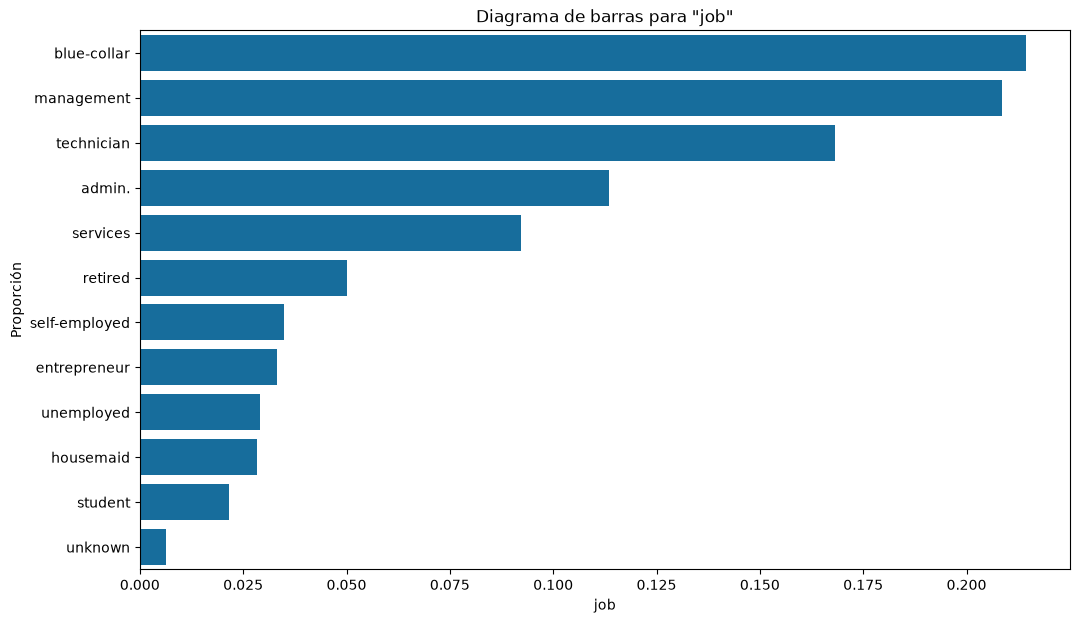

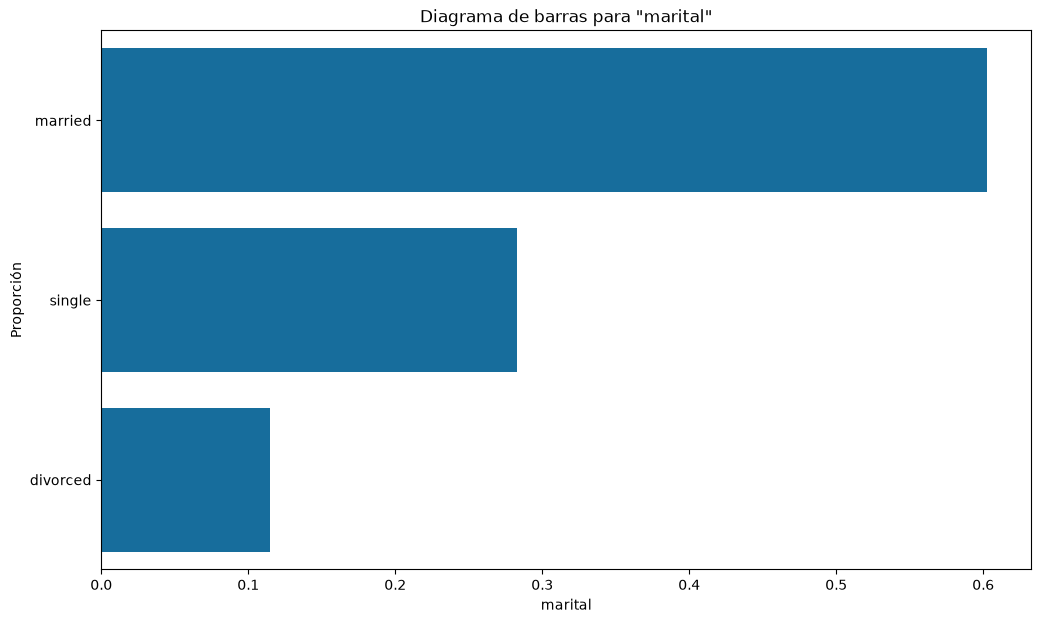

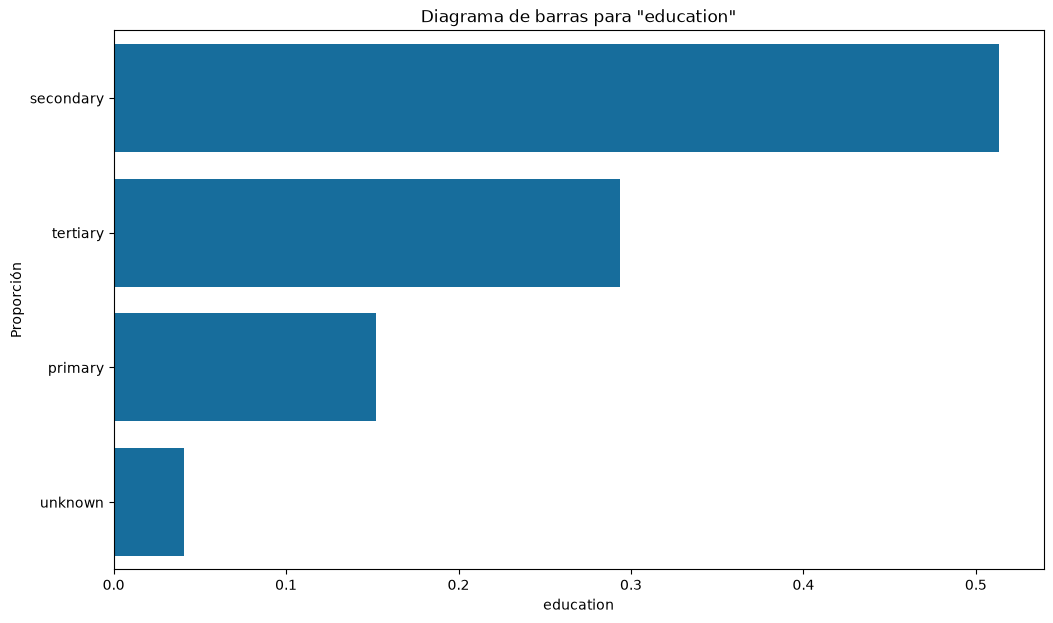

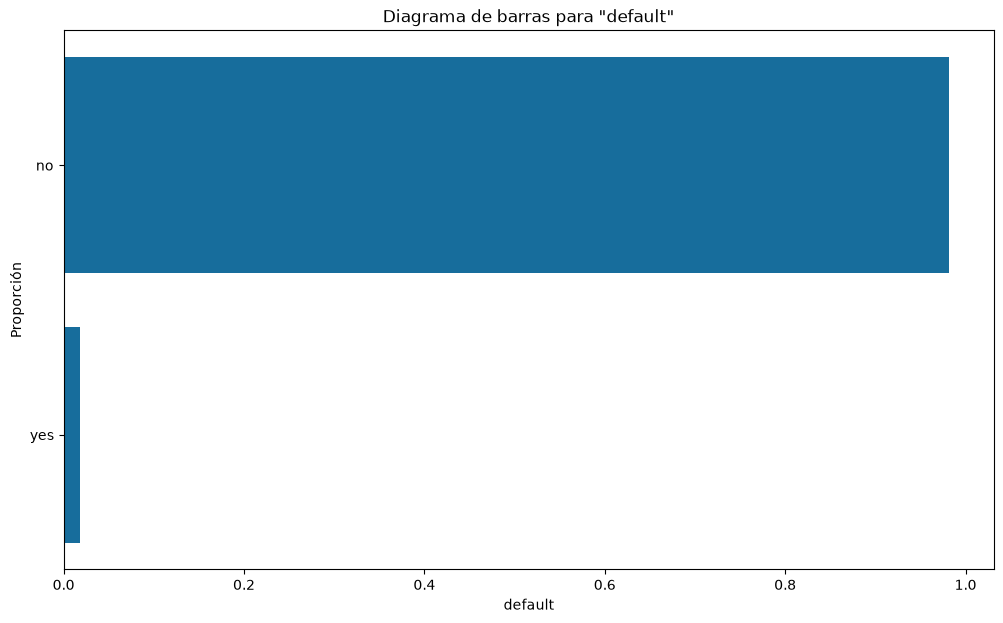

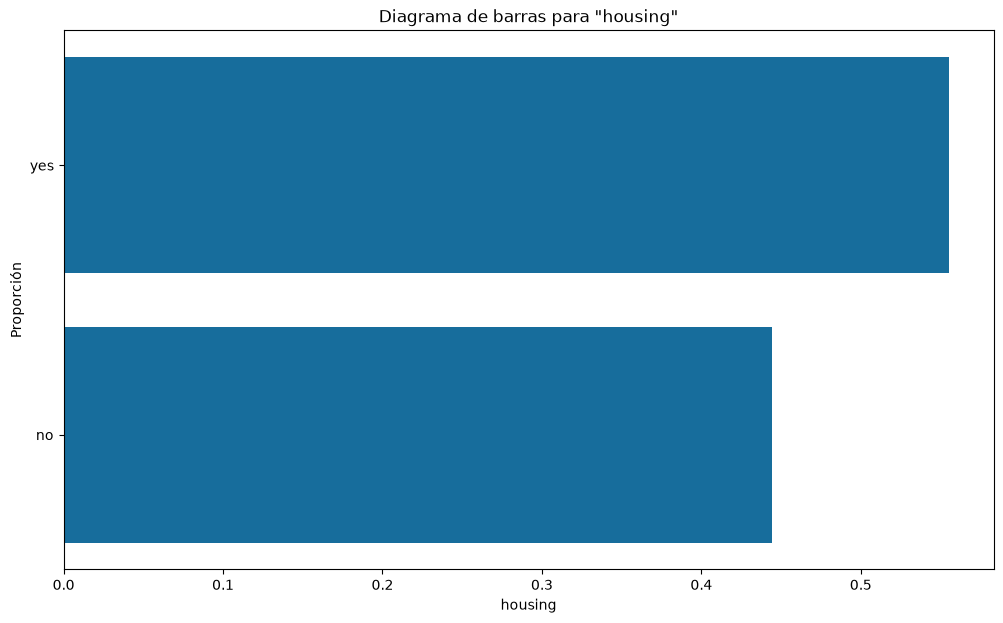

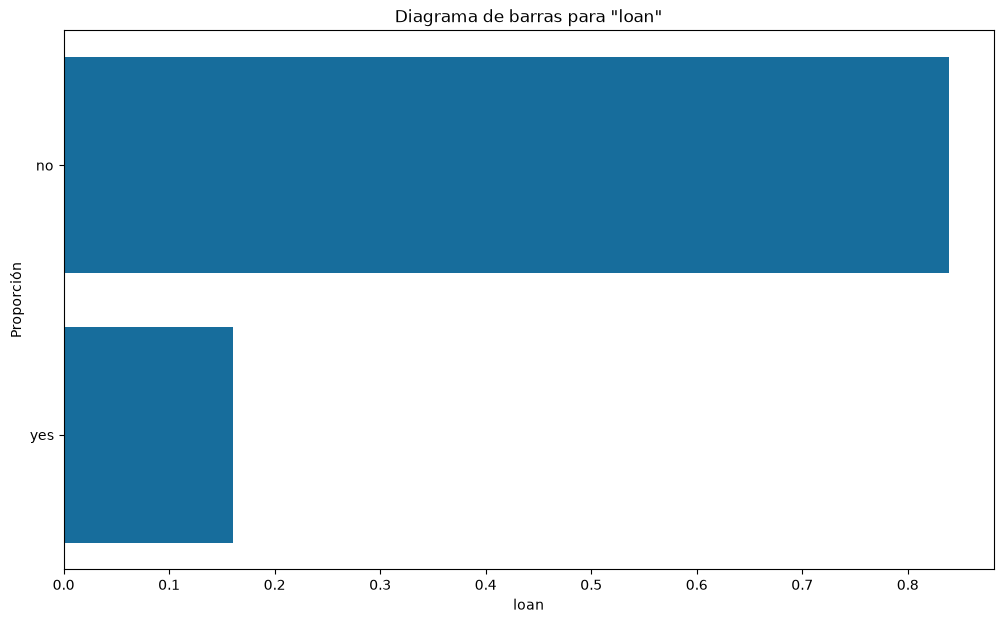

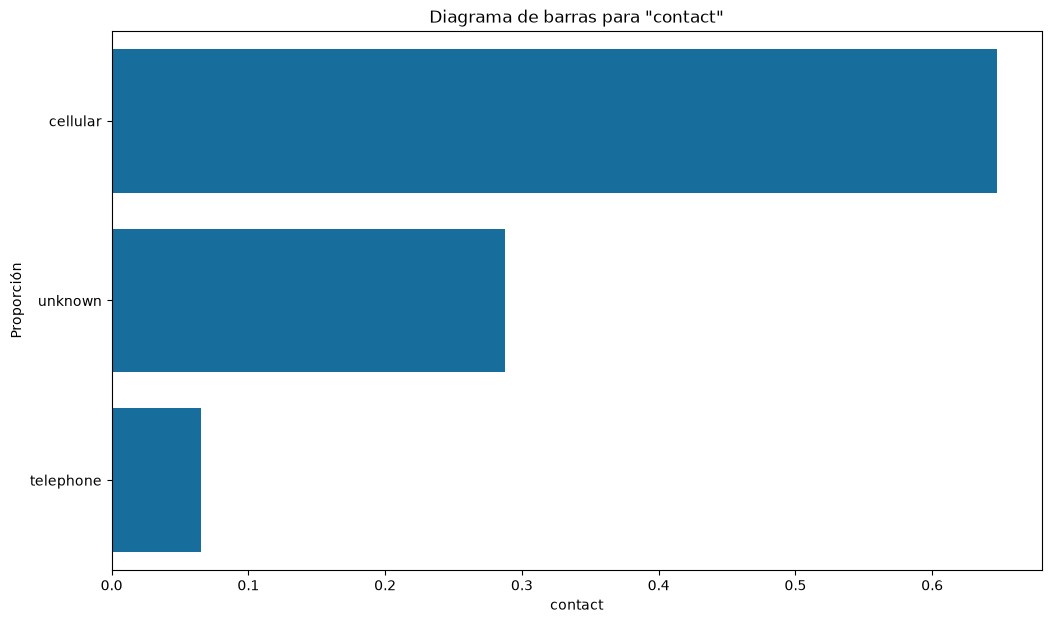

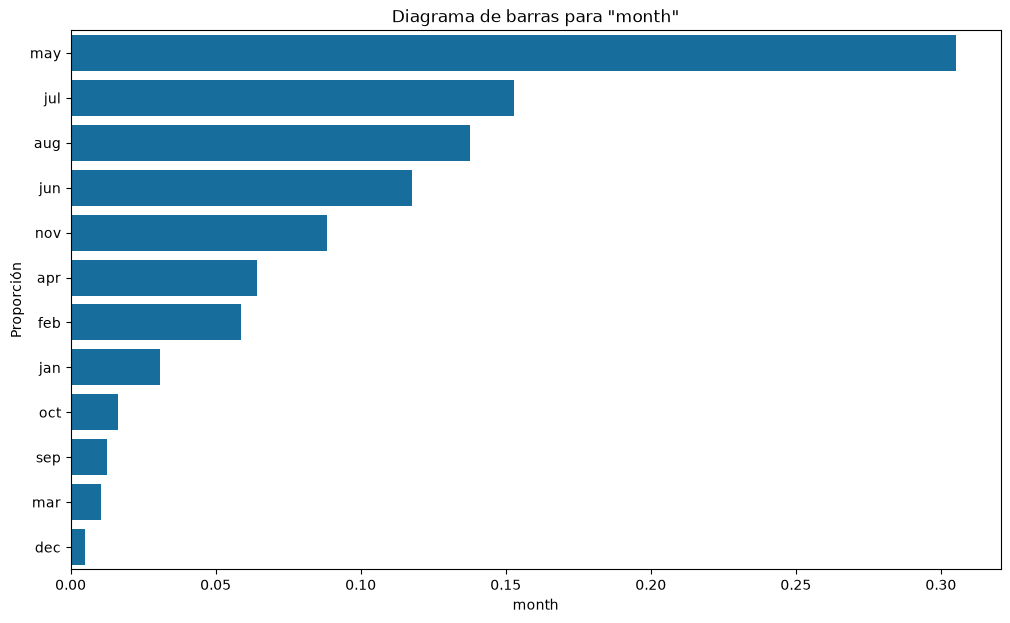

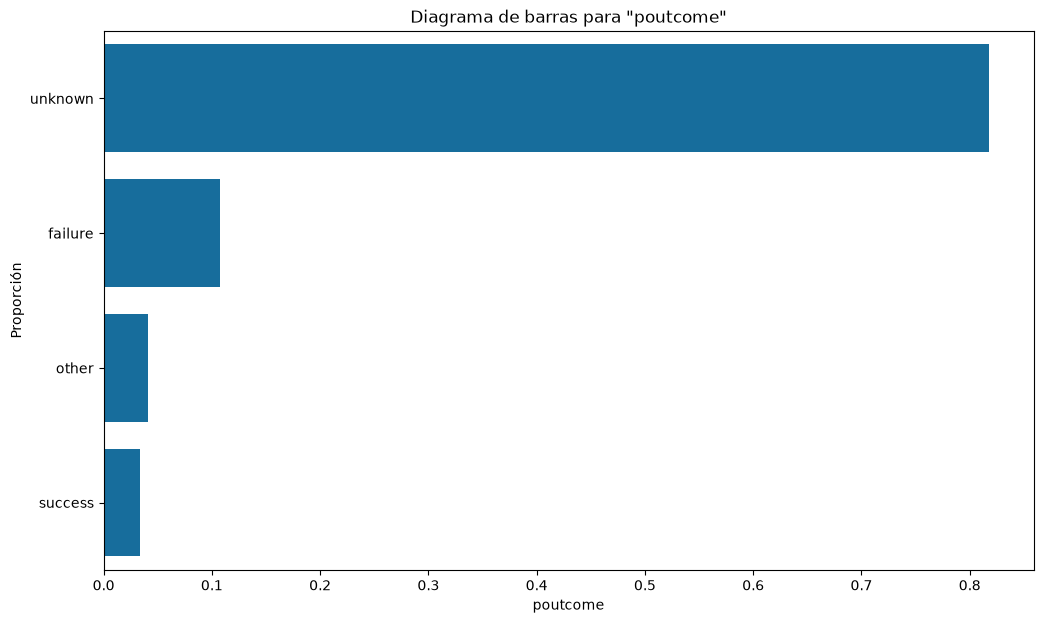

In [26]:
for column in categorical_features:
    # Set up the figure
    plt.figure()

    # Plot: Count plot
    y = X_train[column]
    order = X_train[column].value_counts().index  # Sort the bars by frequency for better readability
    stat = "proportion"  # Normalize to proportions
    sns.countplot(y=y, order=order, stat=stat)
    title = f'Diagrama de barras para "{column}"'
    xlabel = column
    ylabel = "Proporción"
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

Los gráficos de barras son reveladores:

* **Datos faltantes ocultos (`"unknown"`):** Hemos identificado la presencia explícita de la categoría `"unknown"` en:
    * `job`: Una barra muy pequeña (frecuencia baja).
    * `education`: Una barra muy pequeña (frecuencia baja).
    * `contact`: Una barra de tamaño considerable (frecuencia media).
    * `poutcome`: La barra dominante. Más del 80% de los datos en esta columna son `"unknown"`.

* **Estrategias de codificación:**
    * **`job`, `marital`, `contact`, `month`:** Tienen múltiples categorías sin un orden inherente claro. Son candidatas para *one-hot encoding*.
    * **`education`:** Tiene un orden claro (`"primary"` < `"secondary"` < `"tertiary"`). Es candidata para *ordinal encoding*. La dificultad es dónde colocar `"unknown"`: por simplicidad, lo situaremos al final del orden, aunque es una decisión discutible.
    * **`default`, `housing`, `loan`:** Son binarias (`"yes"` y `"no"`). Las codificaremos como `0` (`"no"`) y `1` (`"yes"`).

* **Columnas a tratar:**
    * **`poutcome`:** Con más del 80% de sus valores siendo `"unknown"`, a primera vista parece prácticamente inútil para la predicción, y la decisión más inmediata sería **eliminarla**. No obstante, antes de descartar una variable conviene preguntarse **por qué** falta el dato. Lo revisaremos en la sección 3.6.
    * **`contact`:** Tiene un alto número de `"unknown"`. No la eliminaremos, ya que puede ser una categoría informativa en sí misma (quizá el banco no tiene ese dato por una razón).

### 3.3. Análisis y manejo de valores faltantes

Como vimos antes, este conjunto de datos no tiene valores nulos explícitos (del tipo `NaN`). En su lugar, los valores faltantes están **ocultos bajo `"unknown"`**.

Ahora podemos usar `missingno` para visualizar la magnitud y la estructura de estas ausencias. En particular, usaremos `msno.matrix()`, que muestra una matriz de todo el conjunto de datos. Las zonas oscuras representan datos presentes y las **líneas blancas, datos faltantes**. Nos permite ver patrones: ¿tienden a faltar valores en las mismas filas?

<Axes: >

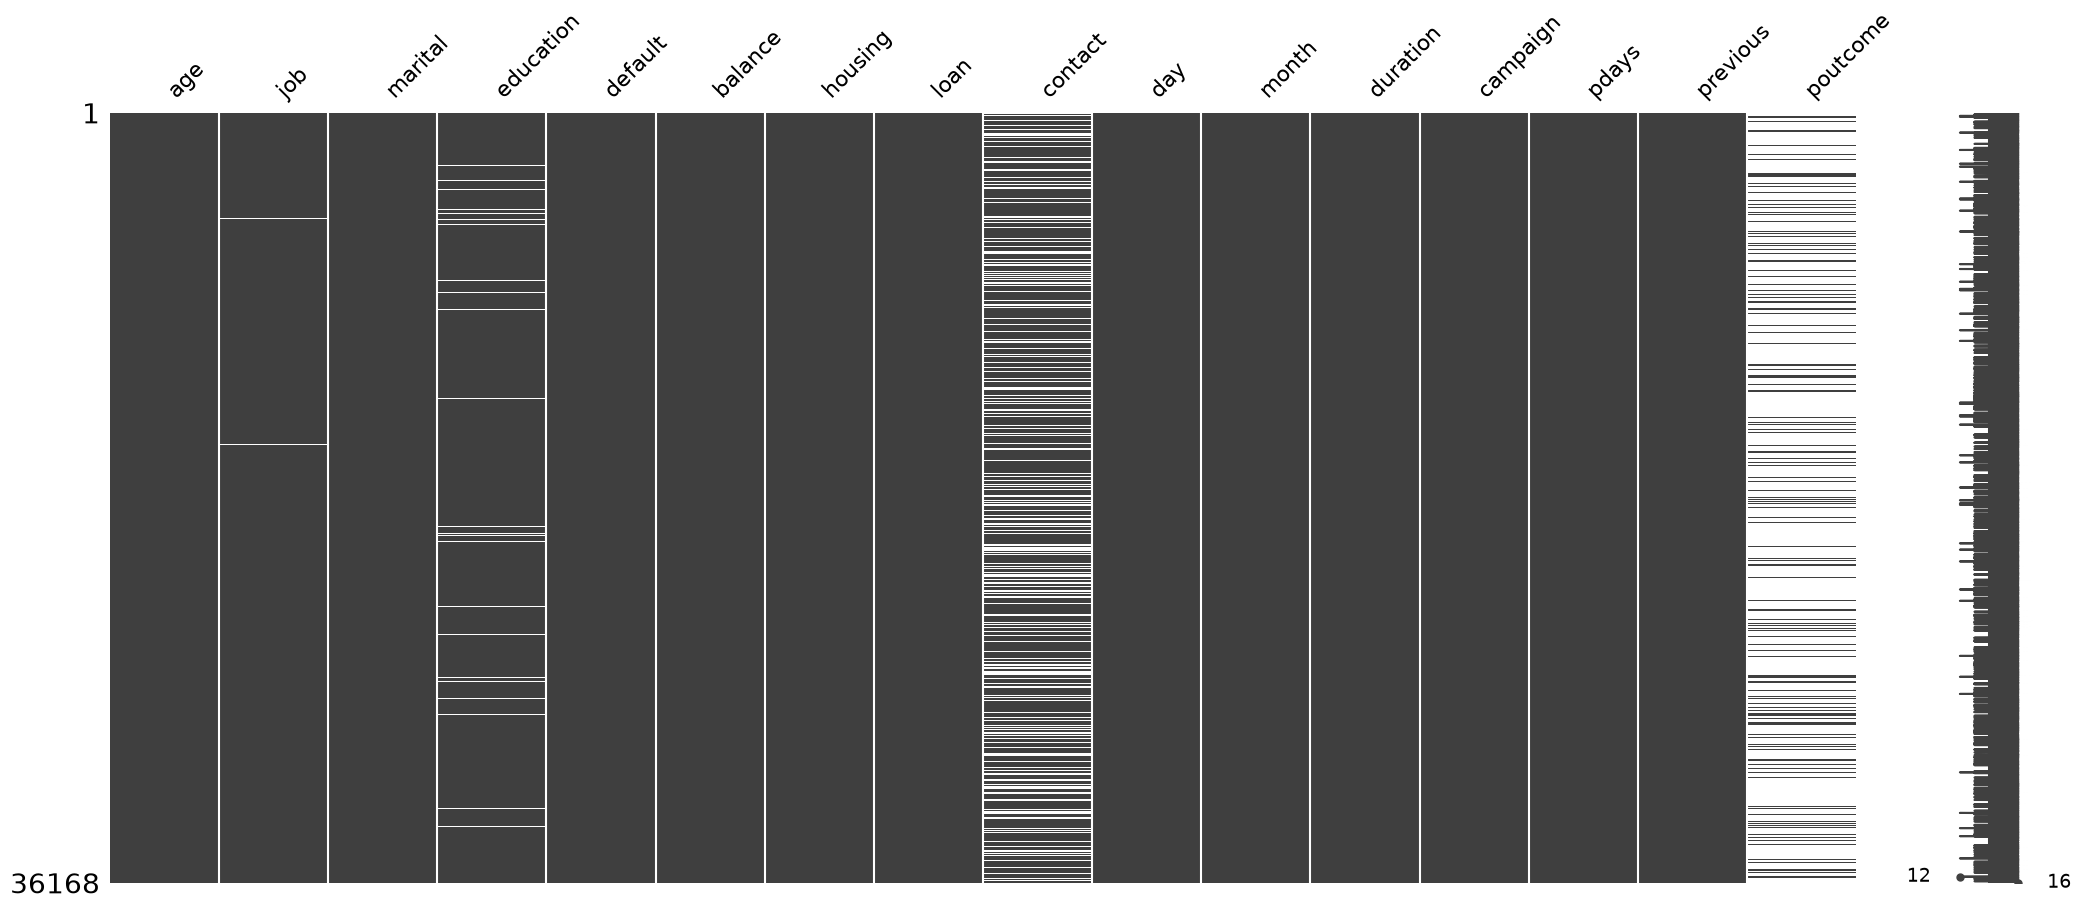

In [27]:
df = X_train.copy()
mapping = {"unknown": pd.NA}
df = df.replace(mapping)
msno.matrix(df)

Este gráfico de `missingno` es muy claro y nos permite definir la estrategia final:

* **`poutcome`:** El gráfico de matriz muestra esta columna como casi completamente **blanca** (vacía).
    * **Estrategia (provisional):** **Eliminar la columna**, ya que parece irrecuperable. Pero cuidado: un porcentaje alto de «faltantes» no implica necesariamente que la variable no aporte información. Revisaremos esta decisión en la sección 3.6.

* **`contact`:** Vemos una cantidad significativa de líneas blancas. Crucialmente, la matriz **no** muestra una correlación fuerte con otros faltantes (es decir, las líneas blancas en `contact` no siempre coinciden con las de `education` o `job`).
    * **Estrategia:** La falta de este dato es probablemente informativa. No la imputaremos con la moda. La estrategia será **tratar el nulo como una categoría separada**.

* **`job` y `education`:** La matriz apenas muestra líneas blancas.
    * **Estrategia:** La cantidad es muy baja. En `education`, como en `contact`, **trataremos el nulo como una categoría separada**. En `job`, al ser tan pocos, lo agruparemos con otra categoría poco frecuente (sección 4.3).

<div class="alert alert-block alert-success">

**`TODO 4`.** La matriz de `missingno` nos permite ver la estructura de los valores faltantes, pero no los cuantifica. Calcula, para cada variable categórica de `X_train`, el **porcentaje** de instancias con valor `"unknown"`. Anota el de `contact` (con un decimal).

</div>

In [28]:
# TODO 4: Compute the percentage of "unknown" values in each categorical feature of "X_train"

### 3.4. Detección de duplicados e inconsistencias

En esta etapa se identifican registros duplicados y se verifican inconsistencias básicas, como formatos incorrectos o valores fuera de los rangos esperados, con el fin de garantizar la calidad y coherencia del conjunto de entrenamiento. Dado que ya se realizó una revisión de los rangos durante la exploración inicial de las variables, no es necesario repetir este análisis en esta fase.

In [29]:
duplicates = X_train.duplicated()
num_duplicates = duplicates.sum()
print(f"Número de filas duplicadas: {num_duplicates}")

Número de filas duplicadas: 0


Tal como se observa, no existen registros completamente duplicados en `X_train`.

No obstante, también es posible identificar duplicados parciales, es decir, registros que comparten el mismo identificador pero presentan diferencias en otros campos.

In [30]:
# Detect duplicate indices
keep = False  # Mark all duplicates as "True"
mask = X_train.index.duplicated(keep=keep)
duplicated_indices = X_train.index[mask]

# Filter records with duplicate indices
duplicated_records = X_train.loc[duplicated_indices]

# Verify if, for each duplicated index, the records are different
# Group by index and check if there are multiple unique rows
level = 0  # Group by index level
function = lambda group: group.drop_duplicates().shape[0] > 1
grouped = duplicated_records.groupby(level=level).filter(function)

# Display the found records
print("Duplicados parciales (mismo índice, datos diferentes):")
grouped

Duplicados parciales (mismo índice, datos diferentes):


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome


Tampoco se han encontrado registros con índices duplicados que presenten diferencias en sus datos, por lo que el conjunto de datos está limpio en relación con la unicidad de sus identificadores.

### 3.5. Análisis de correlaciones

El análisis de correlaciones nos permite medir la fuerza y dirección de la relación entre variables. Esto permite identificar patrones, seleccionar variables relevantes y detectar posibles redundancias o multicolinealidad que podrían afectar la interpretación y rendimiento de los modelos predictivos.

A continuación visualizaremos con un mapa de calor la matriz de correlaciones para facilitar su interpretación, usando la librería `dython` que permite interpretar correctamente las relaciones entre variables de distinto tipo.

<div class="alert alert-block alert-warning">

La correlación mide **asociación**, no **causalidad**.

</div>

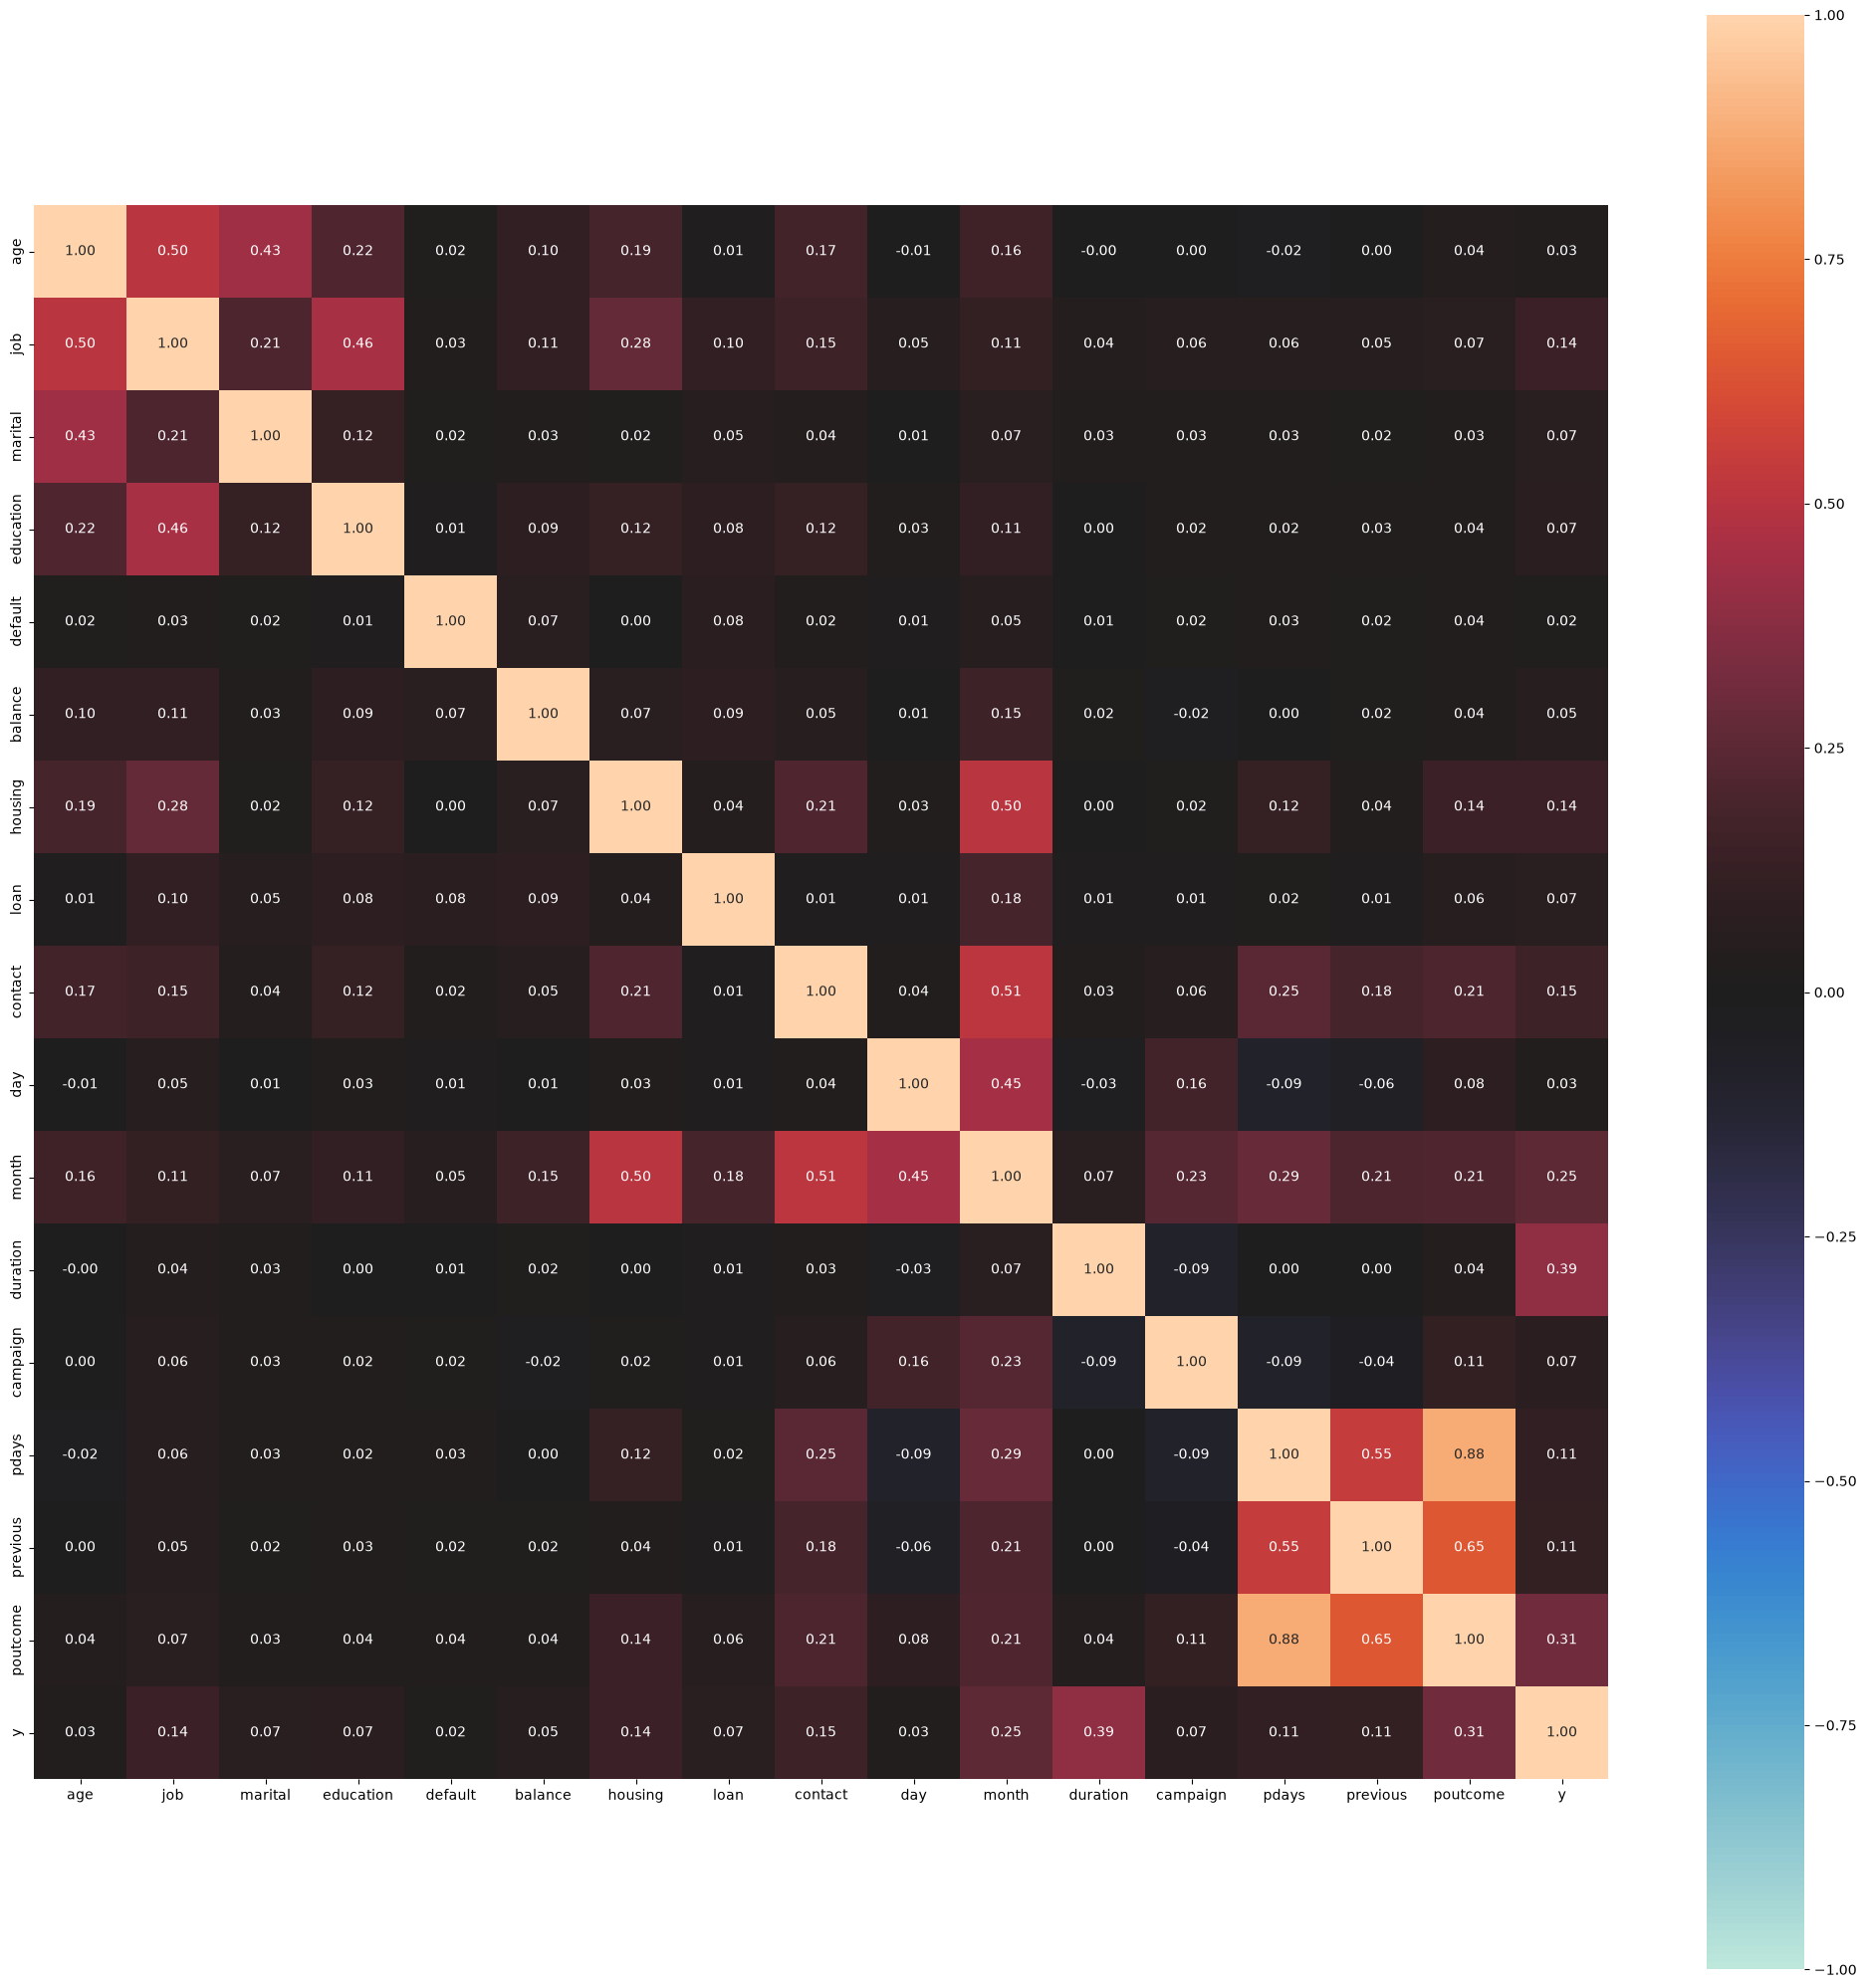

In [31]:
df = X_train.copy()
loc = df.shape[1]  # Insertion index
df.insert(loc, target, y_train)
_ = associations(df)

* **Relaciones entre la variable objetivo (`y`) y las variables predictoras:**
    * **`y` y `poutcome`:** Muestran una asociación moderada (`0.31`), la mayor tras `duration`. Indica que la distribución de `poutcome` difiere claramente entre los clientes que se suscribieron a un depósito a plazo fijo y los que no. Es decir, el resultado de la campaña previa está estrechamente vinculado al resultado de la actual.
    * **`y` y `duration`:** Presentan la asociación más alta (`0.39`). Esto sugiere que la duración del último contacto también varía de forma notable entre las dos clases de `y`.
    * **`y` y variables demográficas (`age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan`):** Todas muestran asociaciones muy débiles. Esto indica que, en promedio, estas características no difieren significativamente entre las clases de `y`. Por ejemplo, la edad media o el saldo promedio son similares en ambos grupos.
    * **`y` y variables de campaña (`contact`, `day`, `month`, `campaign`, `pdays`, `previous`):** Las asociaciones son bajas, salvo con `month` (`0.25`) y, en menor medida, con `contact`. Esto sugiere que el mes y el canal del último contacto tienen cierta relación con el resultado, aunque no determinante.

* **Relaciones entre variables predictoras:**
    * `pdays` y `previous` están moderadamente asociadas. No es casualidad: los clientes no contactados previamente tienen, a la vez, `pdays = -1` y `previous = 0`, por lo que ambas variables codifican en parte la misma información.
    * `pdays` y `poutcome` tienen una asociación muy alta. Lo investigaremos en la sección 3.6.
    * `month` muestra asociaciones altas con `housing`, `contact` y `day`: ciertos meses coinciden sistemáticamente con ciertos tipos de contacto o con la posesión de préstamo hipotecario.
    * `job` y `education` tienen una asociación clara, lo que refleja que ciertos niveles educativos son comunes en ciertas ocupaciones.
    * `age` y `job` también se asocian, lo que sugiere que algunas profesiones predominan en ciertos rangos de edad.

* **`duration` respecto al resto:** Muestra una asociación muy baja con el resto de las variables, lo que indica que no está determinada por características del cliente como la edad, el empleo o el saldo. Sin embargo, si `duration = 0`, entonces `y = "no"`; y a mayor duración, mayor probabilidad de que `y = "yes"`. **Pero hay un punto crucial:** el objetivo del modelo es identificar **qué clientes van a suscribirse *antes* de realizar la llamada**. Como la duración de la llamada **no se conoce hasta que la llamada ya ha terminado**, incluirla en el modelo introduciría una **fuga de datos**. Por lo tanto, aunque `duration` puede ser altamente predictiva en los datos históricos, no debe utilizarse en un modelo predictivo realista, ya que viola la condición temporal fundamental: predecir el resultado antes de que ocurra la interacción.

### 3.6. Revisión de la decisión sobre `poutcome`

En las secciones 3.2.2 y 3.3 propusimos, de forma provisional, eliminar `poutcome` porque más del 80% de sus valores son `"unknown"`. Sin embargo, el análisis de correlaciones acaba de mostrar que es una de las variables **más asociadas** con `y`. ¿Cómo puede una variable «casi vacía» estar tan relacionada con la variable objetivo?

La clave está en preguntarse **por qué** falta el dato. `poutcome` es el resultado de la campaña *anterior*, así que solo puede conocerse para los clientes que fueron contactados en ella. Y esa información ya la tenemos: en `pdays`, el valor `-1` indica que el cliente **no** fue contactado previamente. Crucemos ambas variables:

In [32]:
not_previously_contacted = X_train["pdays"] == -1  # Clients not contacted in a previous campaign
not_previously_contacted.name = "not_previously_contacted"

poutcome = X_train["poutcome"]  # Result of the previous campaign

pd.crosstab(poutcome, not_previously_contacted)

not_previously_contacted,False,True
poutcome,,
failure,3877,0
other,1490,0
success,1212,0
unknown,4,29585


Prácticamente todos los `"unknown"` corresponden a clientes con `pdays = -1`. Es decir, en `poutcome` el valor `"unknown"` **no es un dato perdido, sino un dato que no aplica**: el cliente no participó en ninguna campaña anterior, así que no hay resultado que registrar.

Veamos ahora la tasa de suscripción para cada valor de `poutcome`:

In [33]:
normalize = "index"  # Normalize over each row
pd.crosstab(poutcome, y_train, normalize=normalize)

y,no,yes
poutcome,,
failure,0.873356,0.126644
other,0.833557,0.166443
success,0.353135,0.646865
unknown,0.908480,0.091520


La diferencia es enorme: los clientes para los que la campaña anterior fue un éxito (`"success"`) se suscriben con muchísima más frecuencia que el resto.

**Decisión final: no eliminaremos `poutcome`.** Trataremos `"unknown"` como una categoría más, igual que hicimos con `contact`.

<div class="alert alert-block alert-warning">

El análisis exploratorio es un proceso **iterativo**: es habitual que un análisis posterior obligue a revisar una decisión tomada antes. Un porcentaje alto de valores faltantes **no es, por sí solo, motivo suficiente para eliminar una variable**: hay que entender su origen.

</div>

---

## 4. Ingeniería de características

Esta es una de las partes más importantes. En el análisis exploratorio de datos diagnosticamos patrones; ahora vamos a proponer transformaciones y la creación de nuevas variables.

Nuestro objetivo es **justificar** la inclusión de estas transformaciones en nuestro `Pipeline` final. Para ello, crearemos las características y las pasaremos, junto con `y_train`, a una función de visualización que nos permita medir su **poder discriminativo**.

Es decir, queremos ver si la nueva característica que creemos separa bien las clases. Como todas las variables que crearemos son **categóricas**, usaremos un **gráfico de barras normalizado** que nos mostrará, para cada categoría, la proporción de clientes que se suscriben (`"yes"`) y que no (`"no"`). Si la **tasa de suscripción** cambia mucho de una categoría a otra, la variable tiene poder discriminativo.

Si creáramos variables numéricas, usaríamos en su lugar gráficos de densidad o diagramas de caja para comparar sus distribuciones entre las dos clases.

### 4.1. Tratamiento de la variable híbrida `pdays`

* **Análisis:** `pdays` vale `-1` (estado categórico) o `> 0` (valor numérico).
* **Propuesta:** Crearemos una nueva variable binaria `previously_contacted` (`"yes"` si `pdays != -1` y `"no"` si `pdays == -1`).

In [34]:
def plot_discriminative_power_categorical(x, y):
    """Plot the discriminative power of a categorical feature."""
    # Ensure x is a series
    x = x.squeeze()

    # Group by the categorical feature and calculate the value counts
    normalize = True  # Normalize to proportions
    counts = y.groupby(x).value_counts(normalize=normalize)

    # Reset index for better display
    name = "Proportion"
    counts = counts.reset_index(name=name)

    sns.catplot(data=counts, x=x.name, y="Proportion", hue=y.name, kind="bar")

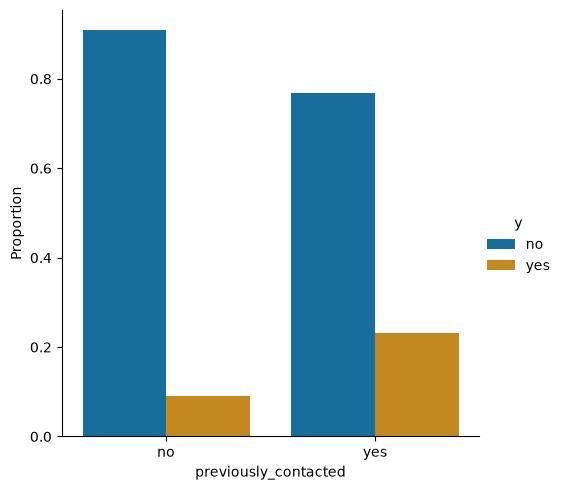

In [35]:
previously_contacted_name = "previously_contacted"  # Name for the new feature
previously_contacted_mapping = {0: "no", 1: "yes"}  # Mapping for previous contact
previously_contacted_function = lambda X: (X["pdays"] != -1).astype(int).map(previously_contacted_mapping).to_frame(name=previously_contacted_name)
previously_contacted = previously_contacted_function(X_train)

plot_discriminative_power_categorical(previously_contacted, y_train)

La tasa de suscripción es **mucho más alta** para los clientes contactados previamente (`previously_contacted = "yes"`).

**Veredicto:** Esta transformación es muy valiosa. La implementaremos en nuestro `Pipeline`.

### 4.2. Agrupación de `age`

* **Análisis:** El efecto de `age` puede no ser lineal.
* **Propuesta:** Agruparemos `age` en rangos para crear la variable `age_group`.

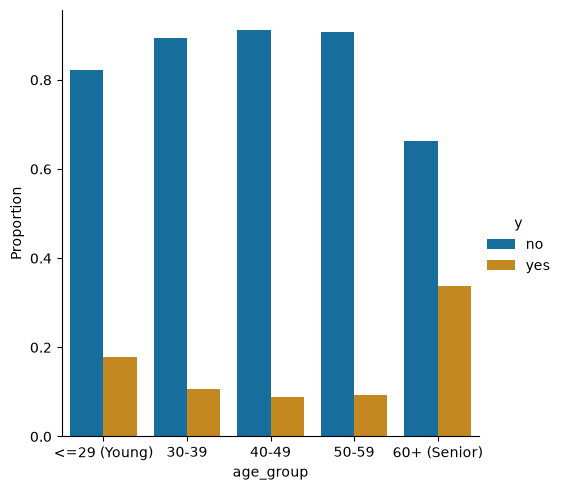

In [36]:
age_group_name = "age_group"
age_group_bins = [-np.inf, 29, 39, 49, 59, np.inf]  # Bins for age groups
age_group_labels = ["<=29 (Young)", "30-39", "40-49", "50-59", "60+ (Senior)"]  # Labels for age groups
age_group_function = lambda X: pd.cut(X["age"], bins=age_group_bins, labels=age_group_labels, right=True).to_frame(name=age_group_name)
age_group_feature = age_group_function(X_train)

plot_discriminative_power_categorical(age_group_feature, y_train)

Nuestra hipótesis se confirma: las tasas de suscripción más altas (barras de `"yes"` más altas) están en los extremos, en los grupos `"60+ (Senior)"` y `"<=29 (Young)"`. Es decir, el efecto de la edad **no es lineal**.

### 4.3. Simplificación de `job`

* **Análisis:** `job` tiene 12 categorías, algunas con frecuencias bajas y conceptualmente similares.
* **Propuesta:** Agruparemos los trabajos en categorías más amplias para crear la variable `job_group`.

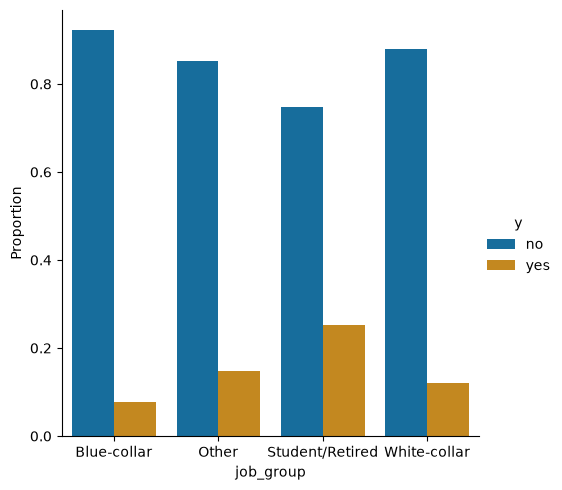

In [37]:
job_group_name = "job_group"
job_group_map = {
    "management": "White-collar", "admin.": "White-collar", "technician": "White-collar", "self-employed": "White-collar", "entrepreneur": "White-collar",
    "blue-collar": "Blue-collar", "services": "Blue-collar", "housemaid": "Blue-collar",
    "student": "Student/Retired", "retired": "Student/Retired",
    "unemployed": "Other", "unknown": "Other"
}

job_group_function = lambda X: X["job"].map(job_group_map).to_frame(name=job_group_name)
job_group_feature = job_group_function(X_train)

plot_discriminative_power_categorical(job_group_feature, y_train)

En coherencia con lo observado con la edad, el grupo `"Student/Retired"` tiene una tasa de suscripción claramente más alta que los demás.

### 4.4. Frecuencia de contacto

* **Análisis:** `campaign` (número de contactos en esta campaña) puede tener un efecto de **rendimientos decrecientes**: insistir demasiado puede ser contraproducente.
* **Propuesta:** Crearemos una variable categórica `contact_frequency` (frecuencia de contacto).

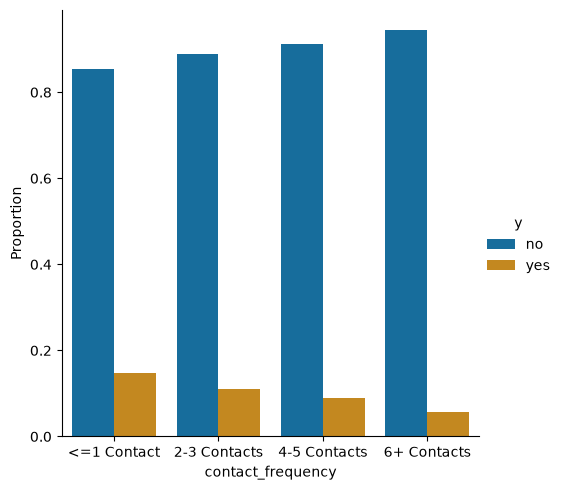

In [38]:
contact_frequency_name = "contact_frequency"
contact_frequency_bins = [-np.inf, 1, 3, 5, np.inf]
contact_frequency_labels = ["<=1 Contact", "2-3 Contacts", "4-5 Contacts", "6+ Contacts"]
contact_frequency_function = lambda X: pd.cut(X["campaign"], bins=contact_frequency_bins, labels=contact_frequency_labels, right=True).to_frame(name=contact_frequency_name)
contact_frequency_feature = contact_frequency_function(X_train)

plot_discriminative_power_categorical(contact_frequency_feature, y_train)

Tal como sospechábamos, la tasa de suscripción es más alta con `"<=1 Contact"` y **cae de forma notable** a medida que aumentan los contactos.

<div class="alert alert-block alert-success">

**`TODO 5`.** Propón una variable nueva a partir de `balance` que indique si el saldo medio anual del cliente es **negativo** o no, y evalúa su poder discriminativo con `plot_discriminative_power_categorical`. No es necesario que la incorpores al `Pipeline`.

* ¿Los clientes con saldo negativo se suscriben más o menos que el resto?
* ¿Tiene sentido desde el punto de vista del negocio?

</div>

In [39]:
# TODO 5: Create a binary feature from "balance" (negative or not) and plot its discriminative power
# negative_balance_name = ...
# negative_balance_function = ...
# negative_balance_feature = ...
# plot_discriminative_power_categorical(negative_balance_feature, y_train)

### 4.5. Estacionalidad

* **Análisis:** El éxito de una campaña de marketing puede depender mucho de la época del año.
* **Propuesta:** Crearemos una variable `season` (estación del año) a partir de `month`.

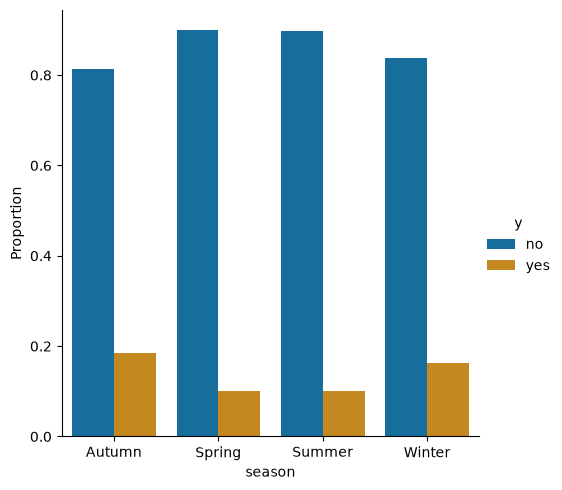

In [40]:
season_name = "season"
season_map = {
    "mar": "Spring", "apr": "Spring", "may": "Spring",
    "jun": "Summer", "jul": "Summer", "aug": "Summer",
    "sep": "Autumn", "oct": "Autumn", "nov": "Autumn",
    "dec": "Winter", "jan": "Winter", "feb": "Winter"
}

season_function = lambda X: X["month"].map(season_map).to_frame(name=season_name)
season_feature = season_function(X_train)

plot_discriminative_power_categorical(season_feature, y_train)

El otoño (`"Autumn"`) y el invierno (`"Winter"`) tienen tasas de suscripción **claramente más altas** que la primavera (`"Spring"`) y el verano (`"Summer"`).

**Veredicto:** Variable estacional relevante. Implementaremos `season`.

Sin embargo, al agrupar los meses en estaciones perdemos detalle. Veamos qué ocurre si miramos directamente cada mes:

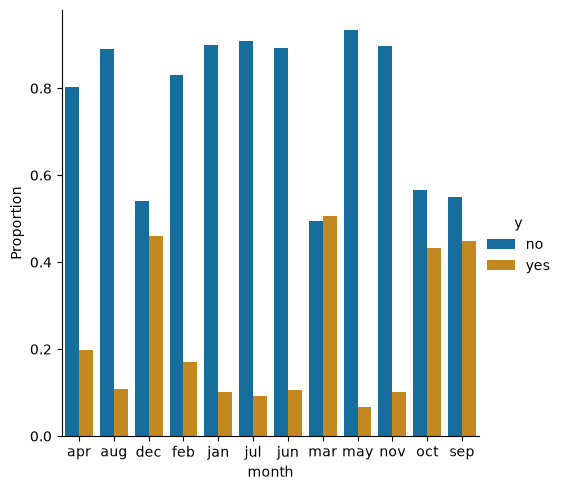

In [41]:
month = X_train["month"]  # Month of the last contact

plot_discriminative_power_categorical(month, y_train)

Dentro de una misma estación hay meses con comportamientos muy diferentes. Por ejemplo, en primavera, marzo (`"mar"`) tiene una tasa de suscripción muy alta, mientras que mayo (`"may"`, el mes con más contactos) tiene una de las más bajas. Si sustituyéramos `month` por `season`, perderíamos esa información.

Por ello, **mantendremos `month`** en el modelo y añadiremos `season` como variable complementaria.

### 4.6. Conclusión

Hemos **identificado** y **validado** cinco transformaciones que generarán nuevas variables con alto poder discriminativo.

Las nuevas variables que implementaremos en nuestro `Pipeline` son:

* `previously_contacted` (de `pdays`)
* `age_group` (de `age`)
* `job_group` (de `job`)
* `contact_frequency` (de `campaign`)
* `season` (de `month`)

Además, **mantendremos `poutcome`** (a diferencia de lo que pensamos inicialmente, con `"unknown"` como una categoría más) y **`month`** (junto a `season`).

---

## 5. Preprocesamiento

Tal y como se puede observar, y siguiendo rigurosamente las buenas prácticas, en ningún momento se ha modificado el conjunto de datos de entrenamiento (`X_train`) durante las fases previas de análisis exploratorio e ingeniería de características. De hecho, en esta fase de preprocesamiento **tampoco** se modificará `X_train` de manera explícita o manual.

En lugar de aplicar transformaciones directas, lo que haremos ahora es definir la *receta* completa de los pasos de preprocesamiento que hemos identificado (imputación, codificación, ingeniería de características, corrección de asimetría y escalado), encapsulando todo el proceso dentro de un único objeto `Pipeline` de `scikit-learn`. Este `Pipeline` utilizará un `ColumnTransformer` para aplicar de forma inteligente las operaciones correctas (`OneHotEncoder` a las categóricas, `StandardScaler` a las numéricas, etc.) a los subconjuntos de columnas adecuados.

Las razones para proceder así son fundamentales y constituyen la piedra angular de un flujo de trabajo de aprendizaje automático robusto:

1. **Evitar la fuga de datos (*data leakage*):** El `Pipeline` garantiza que cualquier estadística necesaria para el preprocesamiento (como la media para el escalado o la moda para la imputación) se aprenda *únicamente* de los datos de entrenamiento (`.fit(X_train, y_train)`) y se aplique de forma consistente a los datos de prueba (`.transform(X_test)`), previniendo que la información del conjunto de prueba «contamine» el modelo.

2. **Reproducibilidad y eficiencia:** Una vez ajustado (`.fit()`), el `Pipeline` se convierte en un objeto autónomo. Ya no es necesario preprocesar manualmente cada conjunto de datos de entrada; solo tendremos que llamar al método `.transform()` sobre el conjunto de prueba o sobre cualquier dato nuevo, asegurando que se aplica exactamente la misma secuencia de pasos sin errores y sin esfuerzo manual.

3. **Integridad en la validación cruzada:** Este es un beneficio crítico. Si quisiéramos ajustar hiperparámetros usando **validación cruzada** (como `GridSearchCV`), hacerlo manualmente sería tedioso y muy propenso a errores. Tendríamos que iterar en cada *fold*, reajustar (`.fit()`) el preprocesador solo en los datos de entrenamiento de ese *fold*, y luego transformar (`.transform()`) los datos de validación de ese *fold*. El `Pipeline` encapsula todo este proceso. Al pasar el `Pipeline` completo a `GridSearchCV`, `scikit-learn` se encarga automáticamente de que, para cada división, todo el *pipeline* (incluido el preprocesamiento) aprenda **únicamente** del subconjunto de entrenamiento de ese *fold*, garantizando que no haya fugas de datos y un código mucho más limpio y robusto.

### 5.1. Diseño de un `Pipeline` de preprocesamiento robusto

La mejor práctica es usar **un único `ColumnTransformer`** que actúe como el preprocesador principal.

El truco es que, dentro de este `ColumnTransformer` único, **cada transformador aplicado a un grupo de atributos puede ser un `Pipeline` en sí mismo**. Esto nos permite aplicar secuencias complejas a un grupo de atributos, y una secuencia diferente a otro grupo, todo en un solo paso y gestionando la salida de atributos de forma limpia.

El diseño sigue cuatro pasos:

#### 5.1.1. Definir las listas de atributos

Lo primero es crear listas de Python que agrupen los atributos por el *tipo exacto de procesamiento* que recibirán. Este es el paso más importante. Basado en nuestro análisis completo, nuestros atributos de entrada a transformar son:

* `numerical_features`: Columnas numéricas que se usan directamente (`balance`, `day`, `previous`). Se tratarán en un *único* `Pipeline`: imputación con mediana → transformación de potencia → escalado estándar.
* `categorical_features_mode_ohe`: Columnas categóricas (`marital`, `month`) que usarán imputación con la **moda** y `OneHotEncoder`.
* `categorical_features_constant_ohe`: Columnas categóricas (`contact`, `poutcome`) que usarán una imputación con **constante** (para tratar `"unknown"` como una categoría) y `OneHotEncoder`.
* `ordinal_features_binary`: Columnas categóricas con un orden binario compartido (`"no"`, `"yes"`). Necesitan imputación (moda) y un `OrdinalEncoder` específico (`default`, `housing`, `loan`).
* `ordinal_features_education`: Columna categórica ordinal con un orden único (`"primary"` < `"secondary"` < `"tertiary"` < `"unknown"`). Necesita su propio `OrdinalEncoder` (`education`).
* **Columnas de ingeniería de características:** Estas listas (`fe_features_pdays`, `fe_feature_age`, `fe_features_job`, `fe_features_campaign`, `fe_features_month`) contienen los *atributos de entrada* (`pdays`, `age`, `job`, `campaign`, `month`) que se enviarán a sus respectivos `Pipeline` de transformación personalizada.
* **Columna a eliminar implícitamente (`duration`):** La forma más fácil de «eliminarla» es simplemente no incluirla en ninguna de las listas anteriores y usar `remainder="drop"` en el `ColumnTransformer`.

<div class="alert alert-block alert-warning">

Aunque nuestro análisis en `X_train` no haya detectado valores perdidos explícitos, es una **buena práctica de producción** incluir un imputador en *todos* los `Pipeline`. Esto los hace robustos: si en el futuro recibimos nuevos datos (para predicción) que *sí* contengan un valor nulo en algún atributo, nuestro `Pipeline` no fallará; simplemente lo imputará y continuará el proceso.

</div>

In [42]:
numerical_features = ["balance", "day", "previous"]

categorical_features_mode_ohe = ["marital", "month"]
categorical_features_constant_ohe = ["contact", "poutcome"]
ordinal_features_binary = ["default", "housing", "loan"]
ordinal_features_education = ["education"]

fe_features_pdays = ["pdays"]
fe_feature_age = ["age"]
fe_features_job = ["job"]
fe_features_campaign = ["campaign"]
fe_features_month = ["month"]

#### 5.1.2. Crear los `Pipeline`

Ahora, para cada lista de atributos, definimos un `Pipeline` de `scikit-learn` que contenga *toda* la secuencia de pasos para ese grupo.

Usaremos `make_pipeline` por simplicidad. Esta función nos ahorra tener que nombrar cada paso y hace el código más limpio.

En los `FunctionTransformer` de ingeniería de características indicaremos, además, el nombre de la variable que generan (`feature_names_out`). Así, `scikit-learn` puede conocer los nombres de las columnas de salida y el resultado final tendrá nombres legibles.

In [43]:
strategy = "median"  # Replace missing values using the median along each column
imputer = SimpleImputer(strategy=strategy)

transformer = PowerTransformer()

scaler = StandardScaler()

numerical_transformer = make_pipeline(imputer, transformer, scaler)

In [44]:
strategy = "most_frequent"  # Replace missing values using the most frequent value along each column
imputer = SimpleImputer(strategy=strategy)

handle_unknown = "ignore"  # When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros
sparse_output = False  # Return dense array instead of sparse matrix
ohe = OneHotEncoder(handle_unknown=handle_unknown, sparse_output=sparse_output)

categorical_transformer_mode_ohe = make_pipeline(imputer, ohe)

In [45]:
strategy = "constant"  # Replace missing values using a constant value
fill_value = "unknown"  # The constant value to use for imputation
imputer = SimpleImputer(strategy=strategy, fill_value=fill_value)

categorical_transformer_constant_ohe = make_pipeline(imputer, ohe)

In [46]:
strategy = "most_frequent"
imputer = SimpleImputer(strategy=strategy)

categories = ["no", "yes"]  # Binary categories for ordinal encoding
categories = [categories for _ in ordinal_features_binary]  # Categories for each feature
encoder = OrdinalEncoder(categories=categories)

ordinal_transformer_binary = make_pipeline(imputer, encoder)

In [47]:
strategy = "constant"
fill_value = "unknown"
imputer = SimpleImputer(strategy=strategy, fill_value=fill_value)

categories = ["primary", "secondary", "tertiary", "unknown"]  # Ordered categories for education
categories = [categories]  # Categories for the feature
encoder = OrdinalEncoder(categories=categories)

ordinal_transformer_education = make_pipeline(imputer, encoder)

In [48]:
strategy = "median"
imputer = SimpleImputer(strategy=strategy)

validate = False  # There is no input validation
feature_names_out = lambda transformer, input_features: [previously_contacted_name]  # Name of the new feature
transformer = FunctionTransformer(previously_contacted_function, validate=validate, feature_names_out=feature_names_out)

fe_transformer_pdays = make_pipeline(imputer, transformer, ohe)

In [49]:
strategy = "median"
imputer = SimpleImputer(strategy=strategy)

feature_names_out = lambda transformer, input_features: [age_group_name]  # Name of the new feature
transformer = FunctionTransformer(age_group_function, validate=validate, feature_names_out=feature_names_out)

fe_transformer_age = make_pipeline(imputer, transformer, ohe)

In [50]:
strategy = "constant"
fill_value = "unknown"
imputer = SimpleImputer(strategy=strategy, fill_value=fill_value)
    
feature_names_out = lambda transformer, input_features: [job_group_name]  # Name of the new feature
transformer = FunctionTransformer(job_group_function, validate=validate, feature_names_out=feature_names_out)

fe_transformer_job = make_pipeline(imputer, transformer, ohe)

In [51]:
strategy = "median"
imputer = SimpleImputer(strategy=strategy)

feature_names_out = lambda transformer, input_features: [contact_frequency_name]  # Name of the new feature
transformer = FunctionTransformer(contact_frequency_function, validate=validate, feature_names_out=feature_names_out)

fe_transformer_campaign = make_pipeline(imputer, transformer, ohe)

In [52]:
strategy = "most_frequent"
imputer = SimpleImputer(strategy=strategy)

feature_names_out = lambda transformer, input_features: [season_name]  # Name of the new feature
transformer = FunctionTransformer(season_function, validate=validate, feature_names_out=feature_names_out)

fe_transformer_month = make_pipeline(imputer, transformer, ohe)

#### 5.1.3. Construir el `ColumnTransformer`

Ahora que tenemos:

1. Las **listas de atributos**.
2. Los **`Pipeline`** de procesamiento.

podemos construir un único `ColumnTransformer`. Usaremos `make_column_transformer` por su simplicidad.

Añadiremos dos argumentos clave al final:

* `remainder="drop"`: Es el **valor por defecto**, pero conviene indicarlo explícitamente. Le dice al transformador que elimine automáticamente cualquier columna que no hayamos mencionado explícitamente en nuestras listas (así es como nos deshacemos de `duration` sin nombrarla).
* `verbose_feature_names_out=False`: Un truco de legibilidad. Evita que `scikit-learn` añada como prefijo el nombre del transformador a nuestras nuevas columnas, dándonos nombres limpios.

In [53]:
remainder = "drop"  # Drop any columns not specified in the transformer
verbose_feature_names_out = False  # Get clean feature names

# Assemble the main preprocessor
preprocessor_final = make_column_transformer(
    # Numerical features
    (numerical_transformer, numerical_features),
    # Ordinal features
    (ordinal_transformer_binary, ordinal_features_binary),
    (ordinal_transformer_education, ordinal_features_education),
    # Categorical features
    (categorical_transformer_constant_ohe, categorical_features_constant_ohe),
    (categorical_transformer_mode_ohe, categorical_features_mode_ohe),
    # Feature engineering features
    (fe_transformer_pdays, fe_features_pdays),
    (fe_transformer_age, fe_feature_age),
    (fe_transformer_job, fe_features_job),
    (fe_transformer_campaign, fe_features_campaign),
    (fe_transformer_month, fe_features_month),
    # Transformer parameters
    remainder=remainder,
    verbose_feature_names_out=verbose_feature_names_out
)

#### 5.1.4. Visualización del resultado

El `preprocessor_final` que acabamos de crear es solo un plan o una *receta*. Aún no ha procesado ningún dato.

Para ver qué produce, vamos a hacer exactamente lo que el `Pipeline` final hará internamente: llamaremos a `.fit_transform()` **solo sobre `X_train`**.

Esto hará dos cosas:

1. **`fit` (aprender):** Aprenderá las medianas, las modas, las medias y desviaciones estándar, y los parámetros de la transformación de potencia, *todo* desde `X_train`.
2. **`transform` (aplicar):** Aplicará todas las transformaciones.

El resultado será el conjunto de datos que recibirá la regresión logística.

In [54]:
preprocessor_final.fit_transform(X_train).sample(n, random_state=random_state)

,balance,day,previous,default,housing,loan,education,contact_cellular,contact_telephone,contact_unknown,...,job_group_Student/Retired,job_group_White-collar,contact_frequency_2-3 Contacts,contact_frequency_4-5 Contacts,contact_frequency_6+ Contacts,contact_frequency_<=1 Contact,season_Autumn,season_Spring,season_Summer,season_Winter
11567,-1.062753,0.442526,-0.471525,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
20636,-0.289760,-0.375922,-0.471525,0.0,0.0,1.0,2.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
16686,0.835404,0.973242,-0.471525,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
23674,-0.267924,1.374689,-0.471525,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5572,-0.426481,0.869900,-0.471525,0.0,1.0,0.0,2.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


### Extra

Antes de finalizar nuestro `Pipeline` complejo, vamos a definir un segundo `Pipeline` mucho más simple.

Al principio de la libreta entrenamos un modelo de referencia con el preprocesamiento mínimo imprescindible. Ahora vamos a definir una *baseline* más exigente: un preprocesamiento básico pero correcto, sin nuestra ingeniería de características. Hemos dedicado mucho esfuerzo a la ingeniería de características (agrupar `age`, mapear `job`, transformar `pdays`, etc.). Pero, ¿cuánto valor añade realmente todo ese trabajo?

Al crear uno básico que simplemente «limpia» los datos (imputa, escala y codifica las columnas *originales*, salvo `duration` y `poutcome`, siguiendo nuestra decisión inicial), podemos entrenar ambos modelos (el básico y el complejo) y comparar sus rendimientos. Si nuestro modelo complejo supera significativamente al básico, habremos **justificado y cuantificado** el valor de nuestra ingeniería de características. Si no lo supera, nos indica que la complejidad añadida no era necesaria.

Este seguirá las buenas prácticas, pero **no usará la transformación de potencia ni ninguna de nuestras transformaciones personalizadas**.

In [55]:
numerical_features_basic = ["age", "balance", "day", "campaign", "pdays", "previous"]
categorical_features_basic = ["job", "marital", "education", "default", "housing", "loan", "contact", "month"]

In [56]:
strategy = "median"
imputer = SimpleImputer(strategy=strategy)

scaler = StandardScaler()

numerical_transformer_basic = make_pipeline(imputer, scaler)

In [57]:
strategy = "most_frequent"
imputer = SimpleImputer(strategy=strategy)

categorical_transformer_basic = make_pipeline(imputer, ohe)

In [58]:
preprocessor_basic = make_column_transformer(
    # Numerical features
    (numerical_transformer_basic, numerical_features_basic),
    # Categorical features
    (categorical_transformer_basic, categorical_features_basic),
    # Transformer parameters
    remainder=remainder,
    verbose_feature_names_out=verbose_feature_names_out
)

In [59]:
preprocessor_basic.fit_transform(X_train).sample(n, random_state=random_state)

,age,balance,day,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep
11567,0.946343,-0.526540,0.382845,-0.246851,-0.410098,-0.302697,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
20636,0.100481,-0.359808,-0.457632,0.074223,-0.410098,-0.302697,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16686,1.040328,0.691542,0.983185,1.358519,-0.410098,-0.302697,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
23674,-0.651397,-0.344328,1.463458,2.321741,-0.410098,-0.302697,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5572,-0.745381,-0.440433,0.863117,0.716371,-0.410098,-0.302697,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


<div class="alert alert-block alert-success">

**`TODO 6`.** Compara el número de columnas que generan `preprocessor_final` y `preprocessor_basic` al transformar `X_train`. Anota el número de columnas de cada uno.

Para el preprocesador final, identifica de qué transformador procede cada grupo de columnas. Pista: una vez ajustado, `ColumnTransformer` tiene el método `get_feature_names_out()` y el atributo `output_indices_`.

</div>

In [60]:
# TODO 6: Compare the number of output columns of "preprocessor_final" and "preprocessor_basic"

---

## 6. Modelado

Ya casi hemos terminado. En esta sección, tomaremos nuestros **preprocesadores** y les añadiremos el **estimador** (el modelo) al final.

Crearemos dos `Pipeline` completos:

1. **`pipeline_final`:** El que utiliza nuestro `preprocessor_final` avanzado con toda la ingeniería de características.
2. **`pipeline_basic`:** Un modelo *baseline* con el preprocesamiento simple (`preprocessor_basic`).

In [61]:
classifier = LogisticRegression(random_state=random_state)
pipeline_final = make_pipeline(preprocessor_final, classifier)
pipeline_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature.

In [62]:
classifier = LogisticRegression(random_state=random_state)
pipeline_basic = make_pipeline(preprocessor_basic, classifier)
pipeline_basic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It i

---

## 7. Evaluación

Llegamos al paso final. Ahora que tenemos nuestros dos `Pipeline` (`pipeline_final` y `pipeline_basic`) completamente definidos, vamos a **evaluarlos** en el conjunto de datos de prueba (`X_test`, `y_test`), que el modelo no ha visto nunca.

Tal y como se comentó anteriormente, nuestro conjunto de datos está **desbalanceado**. Por lo tanto, la tasa de acierto, por sí sola, es engañosa: un modelo que prediga `"no"` el 100% del tiempo tendría una tasa de acierto alta.

Para obtener una visión real del rendimiento, usaremos métricas más robustas obtenidas a través de `classification_report`, que nos dará:

* **Precisión:** De todas las veces que el modelo dijo `"yes"`, ¿cuántas acertó? (importante cuando el coste de un falso positivo es alto).
* **Sensibilidad:** De todos los `"yes"` reales que había, ¿cuántos encontró el modelo? (importante cuando el coste de un falso negativo es alto, como en nuestro caso, donde «perder» un cliente es costoso).
* ***F1-score*:** La media armónica de precisión y sensibilidad.

Además, añadiremos la *ROC-AUC*, una métrica muy utilizada para evaluar clasificadores binarios que, a diferencia de las anteriores, no depende del umbral de decisión.

A continuación, presentamos el informe de clasificación para ambos modelos.

In [63]:
y_pred_final = pipeline_final.predict(X_test)
y_prob_final = pipeline_final.predict_proba(X_test)[:, 1]

In [64]:
target_names = ["no", "yes"]  # Class names for the target variable
classification_report_final = classification_report(y_test, y_pred_final, target_names=target_names)

print(classification_report_final)

              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.65      0.17      0.27      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.58      0.61      9043
weighted avg       0.87      0.89      0.86      9043



In [65]:
auc_final = roc_auc_score(y_test, y_prob_final)
auc_final

0.7669526865708743

In [66]:
y_pred_basic = pipeline_basic.predict(X_test)
y_prob_basic = pipeline_basic.predict_proba(X_test)[:, 1]

In [67]:
classification_report_basic = classification_report(y_test, y_pred_basic, target_names=target_names)
print(classification_report_basic)

              precision    recall  f1-score   support

          no       0.89      0.99      0.94      7985
         yes       0.55      0.09      0.15      1058

    accuracy                           0.88      9043
   macro avg       0.72      0.54      0.54      9043
weighted avg       0.85      0.88      0.85      9043



In [68]:
auc_basic = roc_auc_score(y_test, y_prob_basic)
auc_basic

0.7424457246751648

### 7.1. Comparación con el modelo de referencia

Por último, reunimos en una única tabla las métricas de la clase de interés (`"yes"`) para los tres modelos: el de referencia (sección 2.2), el básico y el final.

In [69]:
pos_label = "yes"  # Class of interest
index = ["Referencia", "Básico", "Final"]  # Model names
y_preds = [y_pred_baseline, y_pred_basic, y_pred_final]  # Predicted classes of each model
y_probs = [y_prob_baseline, y_prob_basic, y_prob_final]  # Predicted probabilities of the class of interest of each model

precisions = [precision_score(y_test, y_pred, pos_label=pos_label) for y_pred in y_preds]
recalls = [recall_score(y_test, y_pred, pos_label=pos_label) for y_pred in y_preds]
f1_scores = [f1_score(y_test, y_pred, pos_label=pos_label) for y_pred in y_preds]
aucs = [roc_auc_score(y_test, y_prob) for y_prob in y_probs]

data_results = {"Precisión": precisions, "Sensibilidad": recalls, "F1-score": f1_scores, "ROC-AUC": aucs}  # Metrics of each model
results = pd.DataFrame(data_results, index=index)

decimals = 3  # Number of decimal places to round to
results.round(decimals)

,Precisión,Sensibilidad,F1-score,ROC-AUC
Referencia,0.588,0.019,0.037,0.719
Básico,0.545,0.085,0.147,0.742
Final,0.647,0.173,0.273,0.767


<div class="alert alert-block alert-success">

**`TODO 7`.** Por defecto, `predict()` asigna la clase `"yes"` cuando la probabilidad estimada es mayor o igual que `0.5`. En nuestro problema, perder un cliente potencial es más costoso que hacer una llamada de más.

Usando `y_prob_final`, calcula la precisión y la sensibilidad del modelo final para los umbrales `0.5`, `0.3`, `0.2` y `0.1`. Anota la sensibilidad con el umbral `0.2` (con dos decimales).

* ¿Qué umbral elegirías y por qué?
* ¿Qué coste tiene esa elección?

</div>

In [70]:
# TODO 7: Compute the precision and recall of the final model for several decision thresholds
# thresholds = [0.5, 0.3, 0.2, 0.1]
# for threshold in thresholds:
#     y_pred_threshold = ...
#     ...

<div class="alert alert-block alert-success">

**`TODO 8`.** Construye una variante de `pipeline_final` **sin** la variable `season` (es decir, sin el transformador `fe_transformer_month`), entrénala y compara su *ROC-AUC* con la del modelo final.

* Explica el resultado teniendo en cuenta cómo se codifican `month` y `season` con *one-hot encoding* y que la regresión logística es un modelo lineal.
* ¿Tendría sentido mantener `season` si usáramos otro modelo, como un árbol de decisión?

</div>

In [71]:
# TODO 8: Build, train and evaluate a variant of "pipeline_final" without the "season" feature

### 7.2. Conclusiones

Ahora sí, podemos responder a la pregunta con la que empezamos la libreta: **¿ha merecido la pena el preprocesamiento?**

* **Modelo de referencia:** Con el preprocesamiento mínimo imprescindible, la regresión logística apenas identifica clientes que se suscriben (sensibilidad de `0.02`) y obtiene una *ROC-AUC* de `0.72`. Además, al no escalar las variables, el optimizador agota el número máximo de iteraciones sin converger (`TODO 1`).
* **Modelo básico:** Simplemente imputando, escalando y codificando las variables originales (y eso que no usa `poutcome`), mejoran la sensibilidad, el *F1-score* y la *ROC-AUC* (`0.74`). La precisión baja ligeramente porque el modelo se «atreve» a predecir `"yes"` más veces. El escalado ya marca la diferencia en un modelo que se entrena mediante optimización basada en gradientes.
* **Modelo final:** Con todo el preprocesamiento derivado del análisis exploratorio, obtenemos el **mejor resultado en todas las métricas** de la clase `"yes"` (*ROC-AUC* de `0.77`, *F1-score* de `0.27`, frente a `0.04` del modelo de referencia).

Es importante entender **de dónde viene la mejora**. Buena parte se debe a decisiones que surgieron del análisis exploratorio: haber revisado la eliminación de `poutcome` (sección 3.6) y haber mantenido el detalle de `month` (sección 4.5). Esa variable, que a primera vista parecía «casi vacía», resultó ser una de las más informativas. En cambio, no todas las transformaciones aportan lo mismo: por ejemplo, para un modelo lineal, `season` no añade información nueva si ya tenemos `month` codificada con *one-hot encoding* (`TODO 8`). Discretizar variables numéricas como `age` o `campaign` también puede *quitar* información granular que un modelo lineal sí sabría aprovechar.

Algunas lecciones generales:

1. **Mide antes de preprocesar.** Sin un modelo de referencia, no sabríamos si nuestras decisiones mejoran o empeoran el modelo.
2. **Entiende los datos antes de eliminarlos.** Un `"unknown"` puede ser un dato perdido o un dato que no aplica, y la diferencia es crucial.
3. **No todo el preprocesamiento aporta valor.** Siguiendo el principio de la **navaja de Ockham**, si una transformación no mejora el modelo, es preferible eliminarla y quedarse con la alternativa más simple.
4. **El preprocesamiento depende del modelo.** Lo que no aporta a un modelo lineal (como algunas discretizaciones) puede ser útil para un modelo no lineal, y viceversa (por ejemplo, el escalado es irrelevante para un árbol de decisión).

Por último, recuerda que estas conclusiones se basan en una única partición entrenamiento/prueba. Para compararlas con mayor rigor, deberíamos usar validación cruzada (Tema 3).